# 18 — Commitment-region probe

Pivot from nb 17. The attention sweep didn't show a sparse "look-back" head set. New hypothesis (**commitment region**): at the *first few tokens* of each labeled code-span there is a strong, linearly-decodable "I am committing to step k" signal in the residual stream. In the middle of the span the signal just persists, and need not be re-asserted.

Setup mirrors nb 16 (Schut-style hinge loss in residual space, layer sweep, shuffled-label control), but the contrast is **within-sample, within-step**:

- **Positive (commitment)**: first $N$ tokens of each step's `gen_token_range`.
- **Negative**:
  - *mid-span tokens of the same step* — controls for sample/function/prompt.
  - *non-span-start line-starts within the step* (lines 2..end of the step's block) — controls for the "newline → indent" syntactic confound. Without this, a probe could just be detecting line boundaries.

We run $N=1$ and $N=3$ in parallel and sweep layers in steps of 4.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import json
import random
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils, env_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "1,2,3,4,6"

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, highlight=False)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logging_utils.configure(level=logging.INFO)

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

2026-06-04 14:36:01 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-04 14:36:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-04 14:36:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-04 14:36:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-04 14:36:01 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-04 14:36:01 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-04 14:36:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-04 14:36:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-04 14:36:25 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load labeled generations

We reuse the oracle labels produced by `scripts/clock/build_multistep_clock_data.py`. Each `LabeledGeneration` carries the full prompt, the generation, and one `StepLabel` per step with `gen_token_range` and `gen_line_range` already resolved against the tokenization of `full_prompt + generation` (add_special_tokens=False).

In [4]:
from src.goals.multistep_data import MultiStepDataset
from src.goals.multistep_label import LabeledGeneration

DATA_ROOT = Path(env_utils.DEFAULT_RESULTS_DIR) / "multistep_clock" / mt.name.split("/")[-1]
DATASET_PATH = Path(env_utils.DEFAULT_DATA_DIR) / "multistep" / "seed.json"

ds = MultiStepDataset.load_dataset(str(DATASET_PATH))
name_to_sample = {s.name: s for s in ds.samples}

MODALITIES = ["modular", "monolithic"]
records = []  # one per (sample, modularity) — only those with valid labels.json
for modularity in MODALITIES:
    mod_dir = DATA_ROOT / modularity
    if not mod_dir.exists():
        print(f"  [warn] missing dir: {mod_dir}")
        continue
    for sample_dir in sorted(mod_dir.iterdir()):
        labels_path = sample_dir / "labels.json"
        if not labels_path.exists():
            continue
        with open(labels_path) as f:
            lab = LabeledGeneration.from_dict(json.load(f))
        if lab.sample_name not in name_to_sample:
            continue
        records.append({
            "sample_name": lab.sample_name,
            "modularity": modularity,
            "labeled": lab,
            "sample": name_to_sample[lab.sample_name],
        })

print(f"loaded {len(records)} labeled (sample, modularity) records")
print(f"  modular:    {sum(r['modularity'] == 'modular'    for r in records)}")
print(f"  monolithic: {sum(r['modularity'] == 'monolithic' for r in records)}")

2026-06-04 14:36:25 src.goals.multistep_data INFO     loaded MultiStepDataset: 106 samples from /disk/u/arnab/Codes/Projects/goals/data/multistep/seed.json
loaded 212 labeled (sample, modularity) records
  modular:    106
  monolithic: 106


## 2. Build positive / negative position sets

For each record we re-tokenize `combined = full_prompt + generation` (with offsets) and, per step, partition the tokens in `gen_token_range` into three roles:

- `span_start` — first $N$ tokens.
- `nonstart_linestart` — first token of each subsequent line in the step's block.
- `mid_span` — the remainder.

The contrast for the probe is `span_start` vs `mid_span ∪ nonstart_linestart`. We keep them tagged so we can analyze the two negative subtypes separately later. For monolithic generations we **skip the last step's labels** (its `gen_token_range` bleeds across the others — see nb 17 hypothesis discussion).

**Autoregressive labeling shift (LAG = 1).** When a step starts at token `t_start`, the late-layer state that encodes "I'm about to commit to a new step" lives at position `t_start − 1`, not `t_start`. The model emits the commitment information *into the next token's logits*; the residual stream at `t_start − 1` is where that intent has already been computed but not yet read out. So all role positions are shifted by `−LAG` before HS extraction. Cross-step overlap (the shifted span_start of step k+1 = `t_end^k − 1`) is resolved by excluding such positions from the negative pools.

**Whitespace-only confound (extra config).** Most lag-shifted span_start positions land on a whitespace token (`\n`, `\n\n`, or an indent). We add a separate config that restricts BOTH positives and negatives to whitespace tokens — positives are whitespace tokens that *precede a new step*, negatives are whitespace tokens that *don't*. This is the tightest confound test: a probe can't win by simply detecting "this is a newline/indent." See §8.

In [5]:
from dataclasses import dataclass

# Autoregressive labeling shift: when a step starts at token t_start, the
# "I am about to commit to a new step" signal lives in the late-layer state of
# position t_start - LAG (the previous token, usually a newline/indent).
# Shift all role positions by -LAG before extracting hidden states.
LAG = 1

@dataclass
class TokenRow:
    sample_name: str
    modularity: str
    step_idx: int
    role: str             # 'span_start' | 'nonstart_linestart' | 'mid_span'
                          # also: 'ws_span_start' | 'ws_other' (whitespace-only confound)
    token_pos: int        # absolute token index in `combined` (already lag-shifted)
    first_token_str: str  # decoded token text at token_pos


def _line_starts_in_range(
    full_prompt: str, generation: str, sl: int, el: int, offsets: list[tuple[int, int]]
) -> list[int]:
    """Token indices into `combined` that are the first non-empty token of each
    line in the 1-based inclusive line range [sl, el] of `generation`."""
    char_offset = len(full_prompt)
    gen_lines = generation.splitlines(keepends=True)
    sl = max(1, sl); el = min(el, len(gen_lines))
    line_starts: list[int] = []
    cum = 0
    for li, line in enumerate(gen_lines, start=1):
        line_start_char = char_offset + cum
        cum += len(line)
        if li < sl or li > el:
            continue
        tok = next(
            (j for j, (a, b) in enumerate(offsets) if a >= line_start_char and b > a),
            None,
        )
        if tok is not None:
            line_starts.append(tok)
    return line_starts


def _collect_shifted_span_starts(lab, is_monolithic: bool, N: int) -> set[int]:
    """All lag-shifted span_start positions across a record's steps. Needed up
    front because the shifted span_start of step k+1 coincides with the last
    pre-shift mid-span position of step k (t_end^k - 1), so we must exclude it
    from the negative pool."""
    n_steps = len(lab.labels)
    out: set[int] = set()
    for i, step in enumerate(lab.labels):
        if is_monolithic and i == n_steps - 1:
            continue
        if step.gen_token_range is None:
            continue
        t_start, t_end = step.gen_token_range
        if t_end - t_start < 2:
            continue
        for t in range(t_start, min(t_start + N, t_end)):
            if t - LAG >= 0:
                out.add(t - LAG)
    return out


def extract_token_rows(record: dict, mt, N: int) -> list[TokenRow]:
    """Partition each step's gen_token_range into role-tagged token positions,
    then shift every position by -LAG (autoregressive labeling).

    For monolithic: skip the last step (its block usually subsumes all prior steps).
    """
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    offsets = [tuple(p) for p in enc["offset_mapping"]]
    input_ids = enc["input_ids"]

    is_monolithic = record["modularity"] == "monolithic"
    n_steps = len(lab.labels)
    shifted_span_starts_all = _collect_shifted_span_starts(lab, is_monolithic, N)

    rows: list[TokenRow] = []
    for i, step in enumerate(lab.labels):
        if is_monolithic and i == n_steps - 1:
            continue
        if step.gen_token_range is None or step.gen_line_range is None:
            continue
        t_start, t_end = step.gen_token_range  # end exclusive
        if t_end - t_start < 2:
            continue

        # Shifted span_start positions for this step.
        span_start_idx = [
            t - LAG for t in range(t_start, min(t_start + N, t_end))
            if t - LAG >= 0
        ]
        first_line_orig = set(range(t_start, min(t_start + N, t_end)))

        sl, el = step.gen_line_range
        line_starts = _line_starts_in_range(
            lab.full_prompt, lab.generation, sl, el, offsets
        )
        # Non-start line-starts (shifted): lines 2..end of step's block.
        nonstart_linestarts_shifted = [
            t - LAG for t in line_starts
            if t_start <= t < t_end and t not in first_line_orig and t - LAG >= 0
        ]
        # Cross-step boundary: drop any that coincide with a span_start in the
        # shifted frame (avoid mislabeling).
        nonstart_linestarts_shifted = [
            t for t in nonstart_linestarts_shifted
            if t not in shifted_span_starts_all
        ]

        # Mid-span (shifted) = shifted step range minus the above and minus any
        # shifted span_start (own step or next-step boundary).
        own_span = set(span_start_idx)
        excluded = own_span | set(nonstart_linestarts_shifted) | shifted_span_starts_all
        mid_span_shifted = [
            t for t in range(t_start - LAG, t_end - LAG)
            if t >= 0 and t not in excluded
        ]

        for t in span_start_idx:
            rows.append(TokenRow(
                sample_name=record["sample_name"],
                modularity=record["modularity"],
                step_idx=i, role="span_start", token_pos=t,
                first_token_str=mt.tokenizer.decode([input_ids[t]]),
            ))
        for t in nonstart_linestarts_shifted:
            rows.append(TokenRow(
                sample_name=record["sample_name"],
                modularity=record["modularity"],
                step_idx=i, role="nonstart_linestart", token_pos=t,
                first_token_str=mt.tokenizer.decode([input_ids[t]]),
            ))
        for t in mid_span_shifted:
            rows.append(TokenRow(
                sample_name=record["sample_name"],
                modularity=record["modularity"],
                step_idx=i, role="mid_span", token_pos=t,
                first_token_str=mt.tokenizer.decode([input_ids[t]]),
            ))
    return rows


def _is_whitespace_tok(tok_str: str) -> bool:
    return len(tok_str) > 0 and tok_str.strip() == ""


def extract_whitespace_rows(record: dict, mt) -> list[TokenRow]:
    """Whitespace-only confound: positives = shifted span_start positions whose
    token is whitespace; negatives = all OTHER whitespace tokens inside the
    union of (shifted) step ranges. Both classes are now lexically of the same
    family (\\n / \\n\\n / indents), so a trivial 'this token is whitespace'
    classifier cannot solve the task."""
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, add_special_tokens=False)
    input_ids = enc["input_ids"]

    is_monolithic = record["modularity"] == "monolithic"
    n_steps = len(lab.labels)
    span_start_shifted = _collect_shifted_span_starts(lab, is_monolithic, N=1)

    rows: list[TokenRow] = []
    seen: set[int] = set()
    for i, step in enumerate(lab.labels):
        if is_monolithic and i == n_steps - 1:
            continue
        if step.gen_token_range is None:
            continue
        t_start, t_end = step.gen_token_range
        if t_end - t_start < 2:
            continue
        for t in range(t_start - LAG, t_end - LAG):
            if t < 0 or t in seen:
                continue
            tok_str = mt.tokenizer.decode([input_ids[t]])
            if not _is_whitespace_tok(tok_str):
                continue
            seen.add(t)
            role = "ws_span_start" if t in span_start_shifted else "ws_other"
            rows.append(TokenRow(
                sample_name=record["sample_name"],
                modularity=record["modularity"],
                step_idx=i, role=role, token_pos=t,
                first_token_str=tok_str,
            ))
    return rows


# Build the three variants in parallel.
N_VALUES = [1, 3]
rows_by_N: dict[int, list[TokenRow]] = {}
for N in N_VALUES:
    all_rows = []
    for r in records:
        all_rows.extend(extract_token_rows(r, mt, N=N))
    rows_by_N[N] = all_rows
    role_counts = pd.Series([r.role for r in all_rows]).value_counts().to_dict()
    print(f"N={N}: {len(all_rows)} rows  {role_counts}")

# Whitespace-only confound rows.
ws_rows: list[TokenRow] = []
for r in records:
    ws_rows.extend(extract_whitespace_rows(r, mt))
ws_role_counts = pd.Series([r.role for r in ws_rows]).value_counts().to_dict()
print(f"ws_only: {len(ws_rows)} rows  {ws_role_counts}")


N=1: 36561 rows  {'mid_span': 32626, 'nonstart_linestart': 3192, 'span_start': 743}
N=3: 36479 rows  {'mid_span': 31058, 'nonstart_linestart': 3192, 'span_start': 2229}
ws_only: 4648 rows  {'ws_other': 4322, 'ws_span_start': 326}


## 3. Extract hidden states

One forward pass per (sample, modularity); fetch residual-stream activations at the swept layers and the union of positions across both $N$ variants. About 212 forward passes total.

In [6]:
from src.functional import get_hs
from src.tokens import prepare_input

LAYERS_SWEEP = list(range(0, mt.n_layer, 4))
if (mt.n_layer - 1) not in LAYERS_SWEEP:
    LAYERS_SWEEP.append(mt.n_layer - 1)
LAYERS_SWEEP = sorted(LAYERS_SWEEP)

# "emb" is a sentinel key for the pure token-embedding hidden state
# (read from mt.embedder_name — no contextual info from any transformer block).
LAYER_KEYS = ["emb"] + LAYERS_SWEEP
print(f"sweeping {len(LAYER_KEYS)} layers: {LAYER_KEYS}")


def layer_key_to_name(L) -> str:
    return mt.embedder_name if L == "emb" else mt.layer_names[L]


def _plot_x(L):
    """Numeric x-coord for plotting. emb → -1 so the curve still draws cleanly."""
    return -1 if L == "emb" else L


def _layer_label(L) -> str:
    return "emb" if L == "emb" else str(L)


def apply_layer_axis(ax, layer_keys=None):
    """Set xticks/labels so emb is rendered as a string at x=-1."""
    keys = list(layer_keys) if layer_keys is not None else LAYER_KEYS
    locs = [_plot_x(L) for L in keys]
    labels = [_layer_label(L) for L in keys]
    ax.set_xticks(locs)
    ax.set_xticklabels(labels, rotation=0)


# All positions we need per record = union of token_pos across all variants
# (N=1, N=3, and the whitespace-only confound).
key = lambda r: (r.sample_name, r.modularity)
positions_per_record: dict[tuple[str, str], set[int]] = {}
for N in N_VALUES:
    for r in rows_by_N[N]:
        positions_per_record.setdefault(key(r), set()).add(r.token_pos)
for r in ws_rows:
    positions_per_record.setdefault(key(r), set()).add(r.token_pos)

# hs_cache[(sample, modularity)] = dict (layer_key -> dict pos -> tensor(d,))
hs_cache: dict[tuple[str, str], dict] = {}

@torch.no_grad()
def cache_one(record: dict):
    k = (record["sample_name"], record["modularity"])
    if k in hs_cache:
        return
    positions = sorted(positions_per_record.get(k, set()))
    if not positions:
        return
    combined = record["labeled"].full_prompt + record["labeled"].generation
    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    layer_names = [layer_key_to_name(L) for L in LAYER_KEYS]
    locations = [(ly, t) for ly in layer_names for t in positions]
    hs_dict = get_hs(mt=mt, input=tokenized, locations=locations, return_dict=True)
    out: dict = {}
    for L, ly in zip(LAYER_KEYS, layer_names):
        out[L] = {
            t: hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float16)
            for t in positions
        }
    hs_cache[k] = out

for r in tqdm(records, desc="hs"):
    try:
        cache_one(r)
    except Exception as e:
        print(f"  [warn] {r['sample_name']}/{r['modularity']}: {e}")

print(f"cached HS for {len(hs_cache)} records ({len(LAYER_KEYS)} layer keys each)")


sweeping 18 layers: ['emb', 0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 63]


hs:   0%|          | 0/212 [00:00<?, ?it/s]

cached HS for 212 records (18 layer keys each)


## 4. Train/test split + constraint sampling

Hold out **whole samples** (not individual tokens) to prevent leakage. A constraint is a pair $(z^+, z^-)$ where $z^+$ is a `span_start` row and $z^-$ is a same-sample, same-modularity `mid_span` or `nonstart_linestart` row. Within-record matching makes the optimizer ignore prompt/function identity.

In [7]:
SEED = 0
TEST_FRAC = 0.2
TRAIN_LIMIT = 10_000
rng = random.Random(SEED)

all_sample_names = sorted({r["sample_name"] for r in records})
shuffled = list(all_sample_names); rng.shuffle(shuffled)
n_test = max(1, int(len(shuffled) * TEST_FRAC))
test_names = set(shuffled[:n_test])
train_names = set(shuffled[n_test:])
print(f"split: train={len(train_names)} test={len(test_names)} samples")

def split_rows(rows: list[TokenRow]):
    train = [r for r in rows if r.sample_name in train_names]
    test  = [r for r in rows if r.sample_name in test_names]
    return train, test

def index_by_record(rows: list[TokenRow]):
    """Group rows by (sample, modularity) → {role: [rows]}."""
    by_rec: dict[tuple[str, str], dict[str, list[TokenRow]]] = {}
    for r in rows:
        d = by_rec.setdefault((r.sample_name, r.modularity), {})
        d.setdefault(r.role, []).append(r)
    return by_rec


def sample_constraints(rows: list[TokenRow], n: int, rng_local: random.Random) -> list[tuple[TokenRow, TokenRow]]:
    """Within-record pairs of (span_start, mid_span ∪ nonstart_linestart)."""
    by_rec = index_by_record(rows)
    eligible = [
        k for k, d in by_rec.items()
        if d.get("span_start") and (d.get("mid_span") or d.get("nonstart_linestart"))
    ]
    if not eligible:
        return []
    pairs = []
    while len(pairs) < n:
        k = rng_local.choice(eligible)
        d = by_rec[k]
        pos_row = rng_local.choice(d["span_start"])
        negs = (d.get("mid_span", []) + d.get("nonstart_linestart", []))
        neg_row = rng_local.choice(negs)
        pairs.append((pos_row, neg_row))
    return pairs


rows_train_by_N, rows_test_by_N, quads_train_by_N = {}, {}, {}
for N in N_VALUES:
    tr, te = split_rows(rows_by_N[N])
    rows_train_by_N[N] = tr
    rows_test_by_N[N]  = te
    quads_train_by_N[N] = sample_constraints(tr, TRAIN_LIMIT, rng)
    print(f"N={N}: train rows={len(tr)} test rows={len(te)} quads={len(quads_train_by_N[N])}")

split: train=85 test=21 samples
N=1: train rows=29384 test rows=7177 quads=10000
N=3: train rows=29328 test rows=7151 quads=10000


## 5. Optimize direction

Schut-style hinge on unit-normalized residual-stream activations. Warm start from $\bar{z}^+ - \bar{z}^-$; project to the sphere after each step.

In [8]:
def hs_at(row: TokenRow, layer_idx: int, normalize: bool = True) -> torch.Tensor:
    k = (row.sample_name, row.modularity)
    h = hs_cache[k][layer_idx][row.token_pos].to(torch.float32)
    if normalize:
        h = h / (h.norm() + 1e-9)
    return h


def stack_rows(rows: list[TokenRow], layer_idx: int, normalize: bool = True) -> torch.Tensor:
    return torch.stack([hs_at(r, layer_idx, normalize) for r in rows], dim=0)


def optimize_direction(
    pos_rows: list[TokenRow],
    neg_rows: list[TokenRow],
    pair_idx: list[tuple[int, int]],
    layer_idx: int,
    *,
    margin: float = 0.1,
    lr: float = 1e-2,
    n_steps: int = 300,
    batch_size: int = 1024,
    seed: int = 0,
    device: str = "cuda",
    random_init: bool = False,
    verbose: bool = False,
):
    Zp = torch.stack([hs_at(pos_rows[i], layer_idx) for i, _ in pair_idx]).to(device)
    Zn = torch.stack([hs_at(neg_rows[j], layer_idx) for _, j in pair_idx]).to(device)
    diffs = (Zp - Zn).contiguous()
    d = diffs.shape[-1]; N = diffs.shape[0]

    if random_init:
        g = torch.Generator(device=device).manual_seed(seed)
        init = torch.randn(d, generator=g, device=device)
    else:
        init = Zp.mean(dim=0) - Zn.mean(dim=0)
    v = (init / (init.norm() + 1e-9)).clone().detach().requires_grad_(True)
    opt = torch.optim.Adam([v], lr=lr)

    hist = {"loss": [], "sat": []}
    for step in range(n_steps):
        idx = torch.randint(0, N, (batch_size,), device=device)
        b = diffs[idx]
        v_unit = v / (v.norm() + 1e-9)
        margins_b = (b * v_unit).sum(dim=-1)
        loss = torch.clamp(margin - margins_b, min=0).mean()
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if step % max(1, n_steps // 20) == 0 or step == n_steps - 1:
            with torch.no_grad():
                v_u = v / (v.norm() + 1e-9)
                sat = ((diffs * v_u).sum(dim=-1) > 0).float().mean().item()
            hist["loss"].append(loss.item()); hist["sat"].append(sat)
            if verbose:
                print(f"  step {step:4d}  loss={loss.item():.4f}  sat={sat:.3f}")
    return (v / (v.norm() + 1e-9)).detach().cpu(), hist


def mean_diff_direction(pos_rows: list[TokenRow], neg_rows: list[TokenRow], layer_idx: int) -> torch.Tensor:
    P = stack_rows(pos_rows, layer_idx)
    Nn = stack_rows(neg_rows, layer_idx)
    v = P.mean(dim=0) - Nn.mean(dim=0)
    return v / (v.norm() + 1e-9)

## 6. Layer sweep — $N=1$ vs $N=3$

For each swept layer, fit a hinge-loss direction on the training quads and score constraint-satisfaction on a held-out batch of test quads.

In [9]:
TEST_QUADS_LIMIT = 4000
MARGIN = 0.1
LR = 1e-2
N_STEPS = 300

def constraint_sat(v: torch.Tensor, pairs: list[tuple[TokenRow, TokenRow]], layer_key) -> float:
    if not pairs:
        return float("nan")
    diffs = torch.stack([hs_at(p, layer_key) - hs_at(n, layer_key) for p, n in pairs])
    return ((diffs * v).sum(dim=-1) > 0).float().mean().item()

sweep_results: dict[int, list[dict]] = {}
for N in N_VALUES:
    tr_rows = rows_train_by_N[N]; te_rows = rows_test_by_N[N]
    quads = quads_train_by_N[N]
    pos_rows_tr = [p for p, _ in quads]
    neg_rows_tr = [n for _, n in quads]
    pair_idx = [(i, i) for i in range(len(quads))]

    test_pairs = sample_constraints(te_rows, TEST_QUADS_LIMIT, random.Random(1))
    rows_out = []
    for L in LAYER_KEYS:
        v_opt, _ = optimize_direction(
            pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
            margin=MARGIN, lr=LR, n_steps=N_STEPS, verbose=False,
        )
        v_md = mean_diff_direction(pos_rows_tr, neg_rows_tr, L)
        sat_tr_opt = constraint_sat(v_opt, quads, L)
        sat_te_opt = constraint_sat(v_opt, test_pairs, L)
        sat_te_md  = constraint_sat(v_md,  test_pairs, L)
        rows_out.append({
            "layer": L, "sat_train_opt": sat_tr_opt,
            "sat_test_opt": sat_te_opt, "sat_test_md": sat_te_md,
            "v_opt": v_opt, "v_md": v_md,
        })
        print(f"N={N} layer={_layer_label(L):>3s}  sat_te_opt={sat_te_opt:.3f}  sat_te_md={sat_te_md:.3f}")
    sweep_results[N] = rows_out


N=1 layer=emb  sat_te_opt=0.989  sat_te_md=0.970
N=1 layer=  0  sat_te_opt=0.993  sat_te_md=0.984
N=1 layer=  4  sat_te_opt=0.993  sat_te_md=0.978
N=1 layer=  8  sat_te_opt=0.993  sat_te_md=0.979
N=1 layer= 12  sat_te_opt=0.994  sat_te_md=0.979
N=1 layer= 16  sat_te_opt=0.993  sat_te_md=0.981
N=1 layer= 20  sat_te_opt=0.995  sat_te_md=0.984
N=1 layer= 24  sat_te_opt=0.994  sat_te_md=0.984
N=1 layer= 28  sat_te_opt=0.996  sat_te_md=0.986
N=1 layer= 32  sat_te_opt=0.995  sat_te_md=0.984
N=1 layer= 36  sat_te_opt=0.994  sat_te_md=0.983
N=1 layer= 40  sat_te_opt=0.998  sat_te_md=0.983
N=1 layer= 44  sat_te_opt=0.998  sat_te_md=0.988
N=1 layer= 48  sat_te_opt=0.997  sat_te_md=0.993
N=1 layer= 52  sat_te_opt=0.997  sat_te_md=0.995
N=1 layer= 56  sat_te_opt=0.997  sat_te_md=0.995
N=1 layer= 60  sat_te_opt=0.996  sat_te_md=0.995
N=1 layer= 63  sat_te_opt=0.996  sat_te_md=0.988
N=3 layer=emb  sat_te_opt=0.928  sat_te_md=0.818
N=3 layer=  0  sat_te_opt=0.949  sat_te_md=0.842
N=3 layer=  4  sat_t

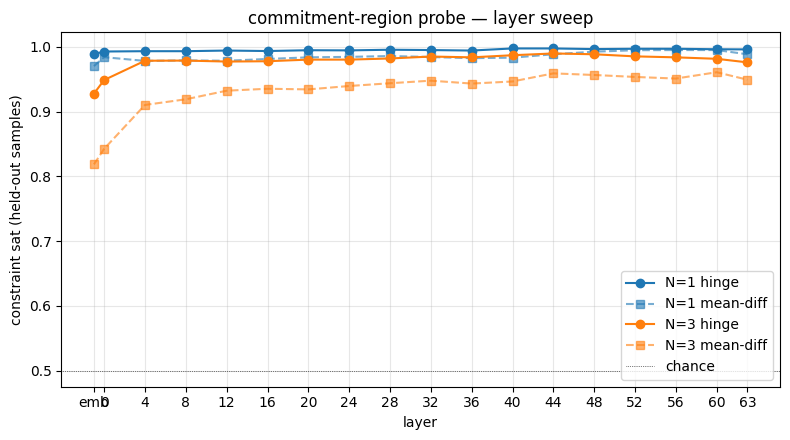

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for N, color in zip(N_VALUES, ["tab:blue", "tab:orange"]):
    df = pd.DataFrame([{k: r[k] for k in r if not k.startswith("v_")} for r in sweep_results[N]])
    df["x"] = df["layer"].map(_plot_x)
    df = df.sort_values("x")
    ax.plot(df["x"], df["sat_test_opt"], "o-", color=color, label=f"N={N} hinge")
    ax.plot(df["x"], df["sat_test_md"],  "s--", color=color, alpha=0.6, label=f"N={N} mean-diff")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (held-out samples)")
ax.set_title("commitment-region probe — layer sweep")
apply_layer_axis(ax)
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 7. Confound checks

1. **Token-identity hold-out**: refit with all `span_start` rows whose first token is `def`, `for`, `if`, `while`, `return` *excluded*. If accuracy collapses, the probe was reading the lexicon.
2. **Shuffled-label control**: random positive/negative assignment within each record. Should sit at chance.

In [11]:
SYNTACTIC_BLACKLIST = {"def", "for", "if", "while", "return", "with", "try", "class"}

def first_tok_clean(s: str) -> str:
    return s.strip().split()[0] if s.strip() else ""

best_layer = {
    N: max(sweep_results[N], key=lambda r: r["sat_test_opt"])["layer"]
    for N in N_VALUES
}
print("best layers per N:", {N: _layer_label(L) for N, L in best_layer.items()})

for N in N_VALUES:
    L = best_layer[N]
    tr_rows = [r for r in rows_train_by_N[N] if not (r.role == "span_start" and first_tok_clean(r.first_token_str) in SYNTACTIC_BLACKLIST)]
    te_rows = [r for r in rows_test_by_N[N]  if not (r.role == "span_start" and first_tok_clean(r.first_token_str) in SYNTACTIC_BLACKLIST)]
    rng_c = random.Random(SEED + 17)
    tr_pairs = sample_constraints(tr_rows, TRAIN_LIMIT, rng_c)
    te_pairs = sample_constraints(te_rows, TEST_QUADS_LIMIT, rng_c)
    pos_rows_tr = [p for p, _ in tr_pairs]
    neg_rows_tr = [n for _, n in tr_pairs]
    v_h, _ = optimize_direction(
        pos_rows_tr, neg_rows_tr, [(i, i) for i in range(len(tr_pairs))],
        layer_idx=L, margin=MARGIN, lr=LR, n_steps=N_STEPS,
    )
    sat_te = constraint_sat(v_h, te_pairs, L)
    print(f"N={N} layer={_layer_label(L)} blacklist-held-out sat_te={sat_te:.3f}")


best layers per N: {1: '40', 3: '44'}
N=1 layer=40 blacklist-held-out sat_te=0.996
N=3 layer=44 blacklist-held-out sat_te=0.994


In [12]:
N_SHUFFLE_SEEDS = 5
for N in N_VALUES:
    L = best_layer[N]
    sats = []
    for s in range(N_SHUFFLE_SEEDS):
        rng_s = random.Random(200 + s)
        rows = rows_train_by_N[N]
        by_rec = index_by_record(rows)
        fake_rows = []
        for k, d in by_rec.items():
            pool = sum(d.values(), [])
            n_pos = len(d.get("span_start", []))
            rng_s.shuffle(pool)
            for i, r in enumerate(pool):
                fake_role = "span_start" if i < n_pos else "mid_span"
                fake_rows.append(TokenRow(
                    r.sample_name, r.modularity, r.step_idx,
                    fake_role, r.token_pos, r.first_token_str,
                ))
        fake_pairs = sample_constraints(fake_rows, TRAIN_LIMIT, rng_s)
        if not fake_pairs:
            continue
        v_f, _ = optimize_direction(
            [p for p, _ in fake_pairs], [n for _, n in fake_pairs],
            [(i, i) for i in range(len(fake_pairs))],
            layer_idx=L, margin=MARGIN, lr=LR, n_steps=N_STEPS, random_init=True, seed=s,
        )
        te_pairs = sample_constraints(rows_test_by_N[N], TEST_QUADS_LIMIT, rng_s)
        sat = constraint_sat(v_f, te_pairs, L)
        sats.append(sat)
    if sats:
        print(f"N={N} layer={_layer_label(L)} shuffled-control sat_te: mean={np.mean(sats):.3f}  std={np.std(sats):.3f}  ({sats})")


N=1 layer=40 shuffled-control sat_te: mean=0.485  std=0.199  ([0.5529999732971191, 0.25725001096725464, 0.824999988079071, 0.46399998664855957, 0.3255000114440918])
N=3 layer=44 shuffled-control sat_te: mean=0.490  std=0.152  ([0.34850001335144043, 0.38600000739097595, 0.778249979019165, 0.44624999165534973, 0.4932500123977661])


## 8. Whitespace-only confound

Restrict both positives and negatives to whitespace tokens (`\n`, `\n\n`, indents). Positives = whitespace tokens immediately preceding a new step; negatives = whitespace tokens elsewhere in the step ranges. A probe can no longer win by lexically detecting "this token is a newline/indent." It must distinguish *which* newline/indent is about to commit to a new step from those that are merely formatting continuation.

Uses the same lag-shifted positions, same within-record matching, same hinge-loss objective, same sweep grid.

> ⚠️ **Open concern:** even within whitespace, the probe could collapse to "is this `\n\n`?" because section-break double-newlines correlate with step boundaries. Diagnostic cell below breaks down test-set sat by token string. If sat is dominated by `\n\n` pairs, augmentation is needed — see §10 below.

In [13]:
# --- Split + sample whitespace-only constraints (loose) -----------------------
ws_tr_rows = [r for r in ws_rows if r.sample_name in train_names]
ws_te_rows = [r for r in ws_rows if r.sample_name in test_names]

def sample_ws_constraints(rows: list[TokenRow], n: int, rng_local: random.Random) -> list[tuple[TokenRow, TokenRow]]:
    by_rec = index_by_record(rows)
    eligible = [
        k for k, d in by_rec.items()
        if d.get("ws_span_start") and d.get("ws_other")
    ]
    if not eligible:
        return []
    pairs = []
    while len(pairs) < n:
        k = rng_local.choice(eligible)
        d = by_rec[k]
        pos_row = rng_local.choice(d["ws_span_start"])
        neg_row = rng_local.choice(d["ws_other"])
        pairs.append((pos_row, neg_row))
    return pairs

rng_ws = random.Random(SEED + 31)
ws_quads_tr = sample_ws_constraints(ws_tr_rows, TRAIN_LIMIT, rng_ws)
ws_quads_te = sample_ws_constraints(ws_te_rows, TEST_QUADS_LIMIT, random.Random(SEED + 32))
print(f"ws_only: train rows={len(ws_tr_rows)} test rows={len(ws_te_rows)} "
      f"quads_tr={len(ws_quads_tr)} quads_te={len(ws_quads_te)}")

# --- Layer sweep ---------------------------------------------------------------
ws_sweep_results: list[dict] = []
pos_rows_tr = [p for p, _ in ws_quads_tr]
neg_rows_tr = [n for _, n in ws_quads_tr]
pair_idx = [(i, i) for i in range(len(ws_quads_tr))]

for L in LAYER_KEYS:
    v_opt, _ = optimize_direction(
        pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
        margin=MARGIN, lr=LR, n_steps=N_STEPS, verbose=False,
    )
    v_md = mean_diff_direction(pos_rows_tr, neg_rows_tr, L)
    sat_tr_opt = constraint_sat(v_opt, ws_quads_tr, L)
    sat_te_opt = constraint_sat(v_opt, ws_quads_te, L)
    sat_te_md  = constraint_sat(v_md,  ws_quads_te, L)
    ws_sweep_results.append({
        "layer": L, "sat_train_opt": sat_tr_opt,
        "sat_test_opt": sat_te_opt, "sat_test_md": sat_te_md,
        "v_opt": v_opt, "v_md": v_md,
    })
    print(f"ws_only layer={_layer_label(L):>3s}  sat_te_opt={sat_te_opt:.3f}  sat_te_md={sat_te_md:.3f}")


ws_only: train rows=3795 test rows=853 quads_tr=10000 quads_te=4000
ws_only layer=emb  sat_te_opt=0.961  sat_te_md=0.961
ws_only layer=  0  sat_te_opt=0.991  sat_te_md=0.981
ws_only layer=  4  sat_te_opt=0.991  sat_te_md=0.985
ws_only layer=  8  sat_te_opt=0.991  sat_te_md=0.988
ws_only layer= 12  sat_te_opt=0.993  sat_te_md=0.983
ws_only layer= 16  sat_te_opt=0.988  sat_te_md=0.992
ws_only layer= 20  sat_te_opt=0.992  sat_te_md=0.996
ws_only layer= 24  sat_te_opt=0.995  sat_te_md=0.994
ws_only layer= 28  sat_te_opt=0.994  sat_te_md=0.995
ws_only layer= 32  sat_te_opt=0.995  sat_te_md=0.995
ws_only layer= 36  sat_te_opt=0.996  sat_te_md=0.993
ws_only layer= 40  sat_te_opt=0.997  sat_te_md=0.984
ws_only layer= 44  sat_te_opt=0.994  sat_te_md=0.986
ws_only layer= 48  sat_te_opt=0.993  sat_te_md=0.992
ws_only layer= 52  sat_te_opt=0.987  sat_te_md=0.996
ws_only layer= 56  sat_te_opt=0.992  sat_te_md=0.996
ws_only layer= 60  sat_te_opt=0.993  sat_te_md=0.987
ws_only layer= 63  sat_te_opt=0

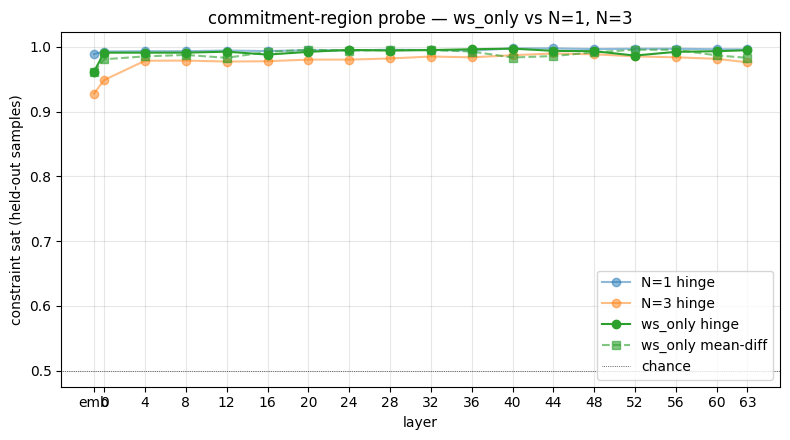

ws_only best layer: 40
ws_only layer=40 shuffled-control sat_te: mean=0.538  std=0.218  ([0.3242500126361847, 0.41749998927116394, 0.34375, 0.7977499961853027, 0.8077499866485596])


In [14]:
# --- Plot: ws_only against N=1, N=3 for context --------------------------------
fig, ax = plt.subplots(figsize=(8, 4.5))
for N, color in zip(N_VALUES, ["tab:blue", "tab:orange"]):
    df = pd.DataFrame([{k: r[k] for k in r if not k.startswith("v_")} for r in sweep_results[N]])
    df["x"] = df["layer"].map(_plot_x); df = df.sort_values("x")
    ax.plot(df["x"], df["sat_test_opt"], "o-", color=color, alpha=0.5, label=f"N={N} hinge")
df_ws = pd.DataFrame([{k: r[k] for k in r if not k.startswith("v_")} for r in ws_sweep_results])
df_ws["x"] = df_ws["layer"].map(_plot_x); df_ws = df_ws.sort_values("x")
ax.plot(df_ws["x"], df_ws["sat_test_opt"], "o-", color="tab:green", label="ws_only hinge")
ax.plot(df_ws["x"], df_ws["sat_test_md"],  "s--", color="tab:green", alpha=0.6, label="ws_only mean-diff")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (held-out samples)")
ax.set_title("commitment-region probe — ws_only vs N=1, N=3")
apply_layer_axis(ax)
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

ws_best_layer = max(ws_sweep_results, key=lambda r: r["sat_test_opt"])["layer"]
print(f"ws_only best layer: {_layer_label(ws_best_layer)}")

# --- Shuffled-label control (ws_only) ------------------------------------------
N_SHUFFLE_SEEDS_WS = 5
sats = []
for s in range(N_SHUFFLE_SEEDS_WS):
    rng_s = random.Random(300 + s)
    by_rec = index_by_record(ws_tr_rows)
    fake_rows = []
    for k, d in by_rec.items():
        pool = sum(d.values(), [])
        n_pos = len(d.get("ws_span_start", []))
        rng_s.shuffle(pool)
        for i, r in enumerate(pool):
            fake_role = "ws_span_start" if i < n_pos else "ws_other"
            fake_rows.append(TokenRow(
                r.sample_name, r.modularity, r.step_idx,
                fake_role, r.token_pos, r.first_token_str,
            ))
    fake_pairs = sample_ws_constraints(fake_rows, TRAIN_LIMIT, rng_s)
    if not fake_pairs:
        continue
    v_f, _ = optimize_direction(
        [p for p, _ in fake_pairs], [n for _, n in fake_pairs],
        [(i, i) for i in range(len(fake_pairs))],
        layer_idx=ws_best_layer, margin=MARGIN, lr=LR, n_steps=N_STEPS,
        random_init=True, seed=s,
    )
    te_pairs = sample_ws_constraints(ws_te_rows, TEST_QUADS_LIMIT, rng_s)
    sat = constraint_sat(v_f, te_pairs, ws_best_layer)
    sats.append(sat)
if sats:
    print(f"ws_only layer={_layer_label(ws_best_layer)} shuffled-control sat_te: "
          f"mean={np.mean(sats):.3f}  std={np.std(sats):.3f}  ({sats})")


### 8.1 Diagnostic — is the probe just a `\n\n` detector?

Two cheap checks before deciding whether to augment:

1. **Counts:** for each token string (`\n`, `\n\n`, `"    "`, …) how many `ws_span_start` and `ws_other` rows do we have? If `\n\n` is almost entirely `ws_span_start` (with ~zero `ws_other`), the probe trivially solves any pair involving `\n\n`.

2. **Conditional sat:** at the best layer, stratify test-set pair accuracy by the **positive's token string**. If sat is high only on `\n\n` pairs and ~chance on `\n` / indent pairs, the probe is a `\n\n` detector. If sat is roughly uniform, the signal is real and we can stop worrying.


In [15]:
# --- Diagnostic 1: per-token-string row counts -------------------------------
from collections import Counter
tok_pos = Counter(r.first_token_str for r in ws_rows if r.role == "ws_span_start")
tok_neg = Counter(r.first_token_str for r in ws_rows if r.role == "ws_other")
all_toks = sorted(set(tok_pos) | set(tok_neg), key=lambda t: -(tok_pos[t] + tok_neg[t]))
print(f"{'token':>12s}  {'span_start':>10s}  {'other':>10s}  {'frac_pos':>9s}")
for t in all_toks:
    p, n = tok_pos[t], tok_neg[t]
    frac = p / (p + n) if (p + n) else 0.0
    print(f"  {repr(t):>10s}  {p:10d}  {n:10d}  {frac:9.3f}")

# --- Diagnostic 2: per-token-string sat on test set at ws_best_layer ----------
v_best = next(r["v_opt"] for r in ws_sweep_results if r["layer"] == ws_best_layer)
te_by_pos_tok: dict[str, list[tuple[TokenRow, TokenRow]]] = {}
for p, n in ws_quads_te:
    te_by_pos_tok.setdefault(p.first_token_str, []).append((p, n))
print(f"\nper-(positive token string) sat at layer {ws_best_layer}:")
print(f"{'pos_tok':>10s}  {'n_pairs':>8s}  {'sat':>7s}")
for tok, qs in sorted(te_by_pos_tok.items(), key=lambda kv: -len(kv[1])):
    if len(qs) < 20:
        continue
    s = constraint_sat(v_best, qs, ws_best_layer)
    print(f"  {repr(tok):>8s}  {len(qs):8d}  {s:7.3f}")

# Same breakdown but conditioned on shared (pos, neg) token-string pair —
# the pairs where pos and neg are the SAME string are the hardest control.
te_by_pair: dict[tuple[str, str], list[tuple[TokenRow, TokenRow]]] = {}
for p, n in ws_quads_te:
    te_by_pair.setdefault((p.first_token_str, n.first_token_str), []).append((p, n))
print(f"\nper-(pos_tok, neg_tok) sat at layer {ws_best_layer} (top buckets):")
print(f"{'pos_tok':>10s}  {'neg_tok':>10s}  {'n':>6s}  {'sat':>7s}  {'same?':>6s}")
for (pt, nt), qs in sorted(te_by_pair.items(), key=lambda kv: -len(kv[1]))[:15]:
    if len(qs) < 20:
        continue
    s = constraint_sat(v_best, qs, ws_best_layer)
    same = "YES" if pt == nt else ""
    print(f"  {repr(pt):>8s}  {repr(nt):>8s}  {len(qs):6d}  {s:7.3f}  {same:>6s}")


       token  span_start       other   frac_pos
       '   '           0        1589      0.000
   '       '           0         940      0.000
         ' '           0         663      0.000
  '           '           0         486      0.000
        '\n'          81         373      0.178
      '\n\n'         245          25      0.907
  '               '           0         178      0.000
  '                   '           0          50      0.000
  '                       '           0          14      0.000
  '                           '           0           2      0.000
  '                  '           0           1      0.000
  '                      '           0           1      0.000

per-(positive token string) sat at layer 40:
   pos_tok   n_pairs      sat
    '\n\n'      2866    0.997
      '\n'      1134    0.997

per-(pos_tok, neg_tok) sat at layer 40 (top buckets):
   pos_tok     neg_tok       n      sat   same?
    '\n\n'     '   '    1270    1.000        
    '\n\n'  

### 8.2 Per-layer same-token sat

If the best-layer same-token sat is real (probe encodes *which* `\n` is committing to a new step, not "is this `\n`?"), it should hold across intermediate layers — not only at layer 63 where the residual stream ≈ output logits.

For each layer in the sweep, evaluate test-set sat on just the two same-token buckets: (`\n`, `\n`) and (`\n\n`, `\n\n`). Layer-0 should be at chance by construction (same token → same embedding → same projection → tie). A clean monotone rise toward middle/late layers = real internal signal. A spike only at the last layer = next-token leakage.

  bucket ('\n', '\n'): n=105
  bucket ('\n\n', '\n\n'): n=49
layer  sat_overall  sat_'\n'  sat_'\n\n'
  emb        0.961     0.000       0.000
    0        0.991     0.781       0.735
    4        0.991     0.752       0.796
    8        0.991     0.743       0.816
   12        0.993     0.790       0.837
   16        0.988     0.657       0.755
   20        0.992     0.838       0.714
   24        0.995     0.924       0.796
   28        0.994     0.905       0.755
   32        0.995     0.905       0.796
   36        0.996     0.962       0.796
   40        0.997     0.981       0.837
   44        0.994     0.829       0.857
   48        0.993     0.876       0.714
   52        0.987     0.743       0.673
   56        0.992     0.819       0.755
   60        0.993     0.857       0.755
   63        0.995     0.895       0.796


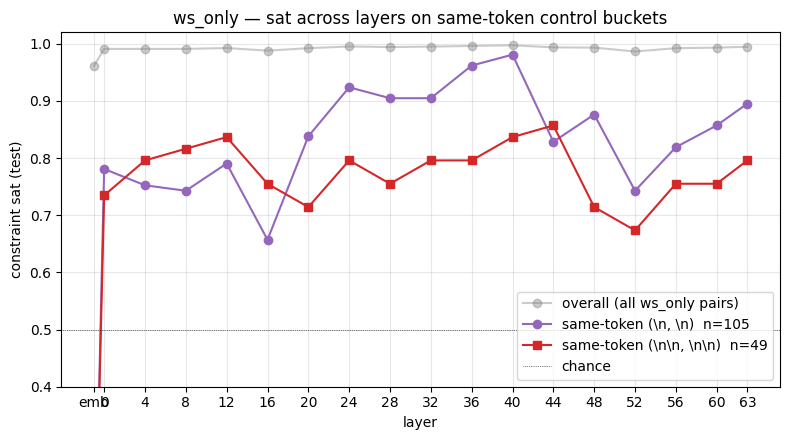

In [16]:
# --- Per-layer sat on same-token buckets --------------------------------------
same_buckets = {
    ("\n", "\n"): [],
    ("\n\n", "\n\n"): [],
}
for p, n in ws_quads_te:
    key2 = (p.first_token_str, n.first_token_str)
    if key2 in same_buckets:
        same_buckets[key2].append((p, n))

for k, v in same_buckets.items():
    print(f"  bucket {repr(k)}: n={len(v)}")

rows_plot = []
for rec in ws_sweep_results:
    L = rec["layer"]
    v_L = rec["v_opt"]
    row = {"layer": L, "sat_overall": rec["sat_test_opt"]}
    for k, qs in same_buckets.items():
        if qs:
            row[f"sat_{repr(k[0])}"] = constraint_sat(v_L, qs, L)
        else:
            row[f"sat_{repr(k[0])}"] = float("nan")
    rows_plot.append(row)

df_layer = pd.DataFrame(rows_plot)
df_layer["x"] = df_layer["layer"].map(_plot_x)
df_layer = df_layer.sort_values("x")
print(df_layer.drop(columns=["x"]).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_layer["x"], df_layer["sat_overall"], "o-", color="tab:gray",
        alpha=0.4, label="overall (all ws_only pairs)")
ax.plot(df_layer["x"], df_layer[f"sat_{repr(chr(10))}"], "o-", color="tab:purple",
        label=f"same-token (\\n, \\n)  n={len(same_buckets[(chr(10), chr(10))])}")
ax.plot(df_layer["x"], df_layer[f"sat_{repr(chr(10)*2)}"], "s-", color="tab:red",
        label=f"same-token (\\n\\n, \\n\\n)  n={len(same_buckets[(chr(10)*2, chr(10)*2)])}")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (test)")
ax.set_title("ws_only — sat across layers on same-token control buckets")
apply_layer_axis(ax, [r["layer"] for r in ws_sweep_results])
ax.legend(loc="lower right"); ax.grid(alpha=0.3); ax.set_ylim(0.4, 1.02)
plt.tight_layout(); plt.show()


In [17]:
mt.embedder_name

'model.embed_tokens'

## 9. Where does the probe fire on a real generation?

Pick a held-out (sample, modularity), do one forward pass to get residual states at **every** token position in the generation range, project onto the trained $v_\text{opt}$ at the best layer, and render with `circuitsvis.colored_tokens`. Ground-truth `span_start` positions are wrapped in `[[ ]]` so we can compare the probe's hot regions against the oracle labels.

Mirrors the visualization pattern from `08_clock.ipynb` cell `1e23d19b` (colored tokens by cosine to probe weight) — but here scores come from $v_\text{opt} \cdot \hat z$ on unit-normalized residuals, matching the training-time objective.

In [72]:
from src.tokens import prepare_input
from rich.table import Table
from rich.text import Text

held_out_records = [r for r in records if r["sample_name"] in test_names]
# demo = held_out_records[12]
demo = [d for d in held_out_records if d["modularity"] == "modular"][2]

rich_print(f"[white]{demo['labeled'].full_prompt}[/white][sea_green3]{demo['labeled'].generation}[/sea_green3]")

full_prompt = demo['labeled'].full_prompt + demo['labeled'].generation
input_ids = prepare_input(prompts=full_prompt, tokenizer=mt).input_ids

table = Table(title=f"step labeling — {demo['labeled'].sample_name}", show_lines=True)
table.add_column("k", justify="right", style="bright_white")
table.add_column("step (truncated)", overflow="fold", max_width=46)
table.add_column("prompt tok", justify="center", style="cyan")
table.add_column("gen line", justify="center", style="yellow")
table.add_column("gen tok", justify="center", style="green")
table.add_column("gen code (truncated)", overflow="fold", max_width=250)

for lbl in demo['labeled'].labels:
    step_short = lbl.step_text if len(lbl.step_text) < 80 else lbl.step_text[:77] + "…"
    p_str = f"{lbl.prompt_token_range[0]}–{lbl.prompt_token_range[1]}" if lbl.prompt_token_range else "—"
    line_str = f"{lbl.gen_line_range[0]}–{lbl.gen_line_range[1]}" if lbl.gen_line_range else "—"
    tok_str = f"{lbl.gen_token_range[0]}–{lbl.gen_token_range[1]}" if lbl.gen_token_range else "—"
    code_short = lbl.gen_code.replace("\n", "↵\n").strip()
    if len(code_short) > 200:
        code_short = code_short[:197] + "…"
    table.add_row(str(lbl.step_idx), step_short, p_str, line_str, tok_str, code_short)

console.print(table)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a python code that does the following:

1. Read the initial height, gravity, damping coefficient, and time step from a config file.
2. Loop in fixed time steps, updating the velocity and position of the ball.
3. Detect each ground contact and apply the damping coefficient to the reflected velocity.
4. Print time, height, and velocity at every step until the ball's energy falls below a tolerance.

Implement each of the above steps as its own well-defined function.
Do not add any comments or docstrings. Only provide the code.<|im_end|>
<|im_start|>assistant
<code>
import json

def read_config(filename):
    with open(filename, 'r') as file:
        config = json.load(file)
    return config['initial_height'], config['gravity'], config['damping_coefficient'], config['time_step']

def update_velocity(velocity, gravity, time_step):
    return velocity - gravity * time_step

def update_position(position, velocity, time_step):
    return position + velocity * time_step

def detect_ground_contact(position, velocity):
    if position <= 0:
        return True, -velocity
    return False, velocity

def apply_damping(velocity, damping_coefficient):
    return velocity * damping_coefficient

def calculate_energy(mass, height, velocity):
    return mass * 9.81 * height + 0.5 * mass * velocity ** 2

def simulate_ball_motion(config_filename, mass, energy_tolerance):
    initial_height, gravity, damping_coefficient, time_step = read_config(config_filename)
    position, velocity, time = initial_height, 0, 0

    while calculate_energy(mass, position, velocity) > energy_tolerance:
        velocity = update_velocity(velocity, gravity, time_step)
        position = update_position(position, velocity, time_step)
        time += time_step

        ground_contact, velocity = detect_ground_contact(position, velocity)
        if ground_contact:
            velocity = apply_damping(velocity, damping_coefficient)
            position = 0

        print(f"Time: {time:.2f}, Height: {position:.2f}, Velocity: {velocity:.2f}")
</code>

                                           step labeling — bouncing_ball                                           
┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ k ┃ step (truncated)                    ┃ prompt tok ┃ gen line ┃ gen tok ┃ gen code (truncated)                ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0 │ Read the initial height, gravity,   │   55–73    │   3–26   │ 166–362 │ def read_config(filename):↵         │
│   │ damping coefficient, and time step  │            │          │         │     with open(filename, 'r') as     │
│   │ from a c…                           │            │          │         │ file:↵                              │
│   │                                     │            │          │         │         config = json.load(file)↵   │
│   │                                     │            │          │         │     return                          │
│   │                                     │            │          │         │ config['initial_height'],           │
│   │                                     │            │          │         │ config['gravity'],                  │
│   │                                     │            │          │         │ config['damping_coefficient'],      │
│   │                                     │            │          │         │ config['t…                          │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 1 │ Loop in fixed time steps, updating  │   75–90    │  29–32   │ 378–423 │ while calculate_energy(mass,        │
│   │ the velocity and position of the    │            │          │         │ position, velocity) >               │
│   │ ball.                               │            │          │         │ energy_tolerance:↵                  │
│   │                                     │            │          │         │         velocity =                  │
│   │                                     │            │          │         │ update_velocity(velocity, gravity,  │
│   │                                     │            │          │         │ time_step)↵                         │
│   │                                     │            │          │         │         position =                  │
│   │                                     │            │          │         │ update_position(position, velocity, │
│   │                                     │            │          │         │ time_s…                             │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 2 │ Detect each ground contact and      │   92–106   │  34–37   │ 424–460 │ ground_contact, velocity =          │
│   │ apply the damping coefficient to    │            │          │         │ detect_ground_contact(position,     │
│   │ the reflected…                      │            │          │         │ velocity)↵                          │
│   │                                     │            │          │         │         if ground_contact:↵         │
│   │                                     │            │          │         │             velocity =              │
│   │                                     │            │          │         │ apply_damping(velocity,             │
│   │                                     │            │          │         │ damping_coefficient)↵               │
│   │                                     │            │          │         │             position = 0↵           │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 3 │ Print time, height, and velocity at │  108–128   │  29–39   │ 378–489 │ while calculate_energy(mass,        │
│   │ every step until the ball's energy  │            │

In [73]:
from circuitsvis.tokens import colored_tokens
from IPython.display import display
from src.attention import _safe_token
from src.tokens import find_token_range

_GLYPH_NL = "\n↵"
_GLYPH_TAB = "⇥"
_GLYPH_DOT = "·"


def _vis_tok(s: str) -> str:
    """Make whitespace tokens visible in display + tooltip (circuitsvis renders
    the same string in both, so non-printable chars need substitution)."""
    s = s.replace("<", "\uff1c").replace(">", "\uff1e")
    s = s.replace("\n", _GLYPH_NL).replace("\r", _GLYPH_NL).replace("\t", _GLYPH_TAB)
    if s.strip() == "" and len(s) > 0:
        s = _GLYPH_DOT * len(s)
    return s


# ─────────────────────────────────────────────────────────────────────────────
# Probe registry — any trained probe set can be plugged in by registering its
# sweep_results list. `register_probe(name, sweep, best_layer, desc)` lets you
# add a custom one in a downstream cell without touching this code.
# ─────────────────────────────────────────────────────────────────────────────

PROBE_REGISTRY: dict[str, dict] = {}


def register_probe(name: str, sweep_results: list[dict], best_layer, desc: str = "") -> None:
    """Register a probe set under `name`. `sweep_results` must be a list of
    dicts each containing keys "layer", "v_opt", "v_md"."""
    PROBE_REGISTRY[name] = {"sweep": sweep_results, "best_layer": best_layer, "desc": desc}


# Auto-register whichever sweeps exist in scope. Guarded so cells that haven't
# been run yet are simply skipped.
def _auto_register():
    g = globals()
    if "sweep_results" in g and "best_layer" in g:
        for N in g.get("N_VALUES", []):
            if N in g["sweep_results"] and N in g["best_layer"]:
                register_probe(f"n{N}", g["sweep_results"][N], g["best_layer"][N],
                               desc=f"N={N} span_start (orig)")
    if "ws_sweep_results" in g and "ws_best_layer" in g:
        register_probe("ws", g["ws_sweep_results"], g["ws_best_layer"],
                       desc="ws_only (orig)")
    if "aug_ws_sweep_results" in g and "aug_ws_best_layer" in g:
        register_probe("ws_aug", g["aug_ws_sweep_results"], g["aug_ws_best_layer"],
                       desc="ws_only (augmented)")

_auto_register()
print("registered probes:")
for k, v in PROBE_REGISTRY.items():
    print(f"  {k:>8s}  best_layer={_layer_label(v['best_layer']):>3s}  {v['desc']}")


def get_v(probe: str, layer=None, kind: str = "opt") -> tuple[torch.Tensor, object]:
    """Return (v, layer_key) for the given probe. layer=None → use best layer.
    kind = 'opt' (hinge-trained) or 'md' (mean-diff)."""
    if probe not in PROBE_REGISTRY:
        raise KeyError(f"unknown probe {probe!r}; available: {list(PROBE_REGISTRY)}")
    entry = PROBE_REGISTRY[probe]
    L = entry["best_layer"] if layer is None else layer
    row = next((r for r in entry["sweep"] if r["layer"] == L), None)
    if row is None:
        avail = [r["layer"] for r in entry["sweep"]]
        raise ValueError(f"probe {probe!r} has no row at layer {L!r}; available: {avail}")
    return row[f"v_{kind}"].to(torch.float32), L


# ─────────────────────────────────────────────────────────────────────────────
# Rendering
# ─────────────────────────────────────────────────────────────────────────────

@torch.no_grad()
def _score_tokens(combined: str, probe: str, layer=None, kind: str = "opt"):
    """Return (input_ids, positions, scores, v, L) for every token in `combined`."""
    v, L = get_v(probe, layer=layer, kind=kind)
    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    input_ids = tokenized.input_ids[0]
    positions = list(range(len(input_ids)))
    ly = layer_key_to_name(L)
    hs_dict = get_hs(
        mt=mt, input=tokenized,
        locations=[(ly, t) for t in positions],
        return_dict=True,
    )
    scores = []
    for t in positions:
        h = hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float32)
        h = h / (h.norm() + 1e-9)
        scores.append((h * v).sum().item())
    return input_ids, positions, scores, v, L


@torch.no_grad()
def render_probe_activity_for_record(
    record, probe: str, layer=None, kind: str = "opt",
    start_from: str | None = None,
):
    """Project the chosen probe onto every token of `full_prompt + generation`
    in `record` and render with circuitsvis. Ground-truth `span_start` tokens
    are wrapped in `[[ ]]` for comparison."""
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    input_ids, _, scores, _, L = _score_tokens(combined, probe, layer=layer, kind=kind)

    start_pos = 0
    if start_from is not None:
        tokenized = prepare_input(prompts=combined, tokenizer=mt, return_offsets_mapping=True)
        offsets = tokenized.pop("offset_mapping")[0]
        start_pos, _ = find_token_range(string=combined, substring=start_from, offset_mapping=offsets)

    tokens = [_vis_tok(mt.tokenizer.decode([tid])) for tid in input_ids]
    span_starts = {s.gen_token_range[0] for s in lab.labels if s.gen_token_range is not None}
    marked = [
        f"[[{tok}]]" if (i + start_pos) in span_starts else tok
        for i, tok in enumerate(tokens[start_pos:])
    ]
    sliced_scores = scores[start_pos:]

    desc = PROBE_REGISTRY[probe]["desc"]
    print(
        f"sample={record['sample_name']}  modularity={record['modularity']}  "
        f"probe={probe} [{desc}]  layer={_layer_label(L)}  kind={kind}"
    )
    print(f"score range: [{min(sliced_scores):.3f}, {max(sliced_scores):.3f}]")
    print("=" * 80)
    display(colored_tokens(
        marked, sliced_scores,
        positive_color="seagreen", negative_color="firebrick",
    ))


@torch.no_grad()
def render_probe_activity_for_text(
    text: str, probe: str, layer=None, kind: str = "opt",
):
    """Project the chosen probe onto every token of `text`."""
    input_ids, _, scores, _, L = _score_tokens(text, probe, layer=layer, kind=kind)
    tokens = [_vis_tok(mt.tokenizer.decode([tid])) for tid in input_ids]
    desc = PROBE_REGISTRY[probe]["desc"]
    print(f"probe={probe} [{desc}]  layer={_layer_label(L)}  kind={kind}")
    print(f"score range: [{min(scores):.3f}, {max(scores):.3f}]")
    print("=" * 80)
    display(colored_tokens(
        tokens, scores,
        positive_color="seagreen", negative_color="firebrick",
    ))


def render_probe_activity_for_record_multi(
    record, probes: list[str], layer=None, kind: str = "opt",
    start_from: str | None = None,
):
    """Render the same record under each named probe in sequence."""
    for p in probes:
        render_probe_activity_for_record(
            record, probe=p, layer=layer, kind=kind, start_from=start_from,
        )


# ─────────────────────────────────────────────────────────────────────────────
# Demo — change DEMO_PROBE / DEMO_LAYER to swap which probe gets visualized.
# DEMO_LAYER=None → each probe's own best layer.
# ─────────────────────────────────────────────────────────────────────────────

DEMO_PROBE = "ws_aug"
DEMO_LAYER = None     # None → probe's own best layer; or set e.g. 44, "emb"
DEMO_KIND  = "opt"
print(f"DEMO_PROBE={DEMO_PROBE}  DEMO_LAYER={DEMO_LAYER}  DEMO_KIND={DEMO_KIND}")

render_probe_activity_for_record(
    demo, probe=DEMO_PROBE, layer=DEMO_LAYER, kind=DEMO_KIND,
    start_from="<code>\n",
)


registered probes:
        n1  best_layer= 40  N=1 span_start (orig)
        n3  best_layer= 44  N=3 span_start (orig)
        ws  best_layer= 40  ws_only (orig)
    ws_aug  best_layer= 56  ws_only (augmented)
DEMO_PROBE=ws_aug  DEMO_LAYER=None  DEMO_KIND=opt
sample=bouncing_ball  modularity=modular  probe=ws_aug [ws_only (augmented)]  layer=56  kind=opt
score range: [-0.071, 0.190]


In [74]:
# rich_print(f"[white]{demo['labeled'].full_prompt}[/white][sea_green3]{demo['labeled'].generation}[/sea_green3]")
full_prompt = demo['labeled'].full_prompt + demo['labeled'].generation

render_probe_activity_for_text(
    full_prompt.replace("\n\n", "\n"), probe=DEMO_PROBE, layer=DEMO_LAYER, kind=DEMO_KIND,
)

# Compare across probes on the same text — uncomment to use:
# render_probe_activity_for_record_multi(
#     demo, probes=["n1", "n3", "ws", "ws_aug"], start_from="<code>\n",
# )


probe=ws_aug [ws_only (augmented)]  layer=56  kind=opt
score range: [-0.072, 0.238]


In [20]:
from src.goals.data import IncompleteCodeSample
from src.goals.goalscope import greedy_continue
from rich.markup import escape
from src.goals.functional import supports_chat_template, apply_chat_template


def get_prompt(sample, mt=mt):
    if supports_chat_template(mt):
        prompt = apply_chat_template(
            mt,
            user_query=sample.full_instruction.strip(),
            incomplete_code=sample.code,
        )
    else:
        prompt = sample.code
    return prompt


# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that sorts a list of numbers in ascending order. Implement it from scratch without using built-in sorting functions.",
#     code="void sort(std::vector<int>& numbers) {",
#     unit_tests=[],
#     function_name="sort",
#     prefills=[],
#     augmentation=None,
# )
test_sample = IncompleteCodeSample(
    instruction="Write a C++ function that gets the shortest distance between two nodes in a graph. Implement it from scratch without using built-in functions.",
    code="int bfs(vector<vector<int>>& graph, int start, int end) {",
    unit_tests=[],
    function_name="bfs",
    prefills=[],
    augmentation=None,
)

test_sample.without_comments = True

test_prompt = get_prompt(test_sample, mt)
test_gen = greedy_continue(
    mt,
    **prepare_input(prompts=test_prompt, tokenizer=mt),
    max_new_tokens=256,
)
rich_print(
    f"[white]{escape(test_prompt)}[/white][sea_green3]{escape(test_gen)}[/sea_green3]"
)


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that gets the shortest distance between two nodes in a graph. Implement it from scratch 
without using built-in functions. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
int bfs(vector<vector<int>>& graph, int start, int end) {  
    int n = graph.size();  
    vector<bool> visited(n, false);  
    vector<int> distance(n, 0);  
    queue<int> q;  
    q.push(start);  
    visited[start] = true;  
    while (!q.empty()) {  
        int u = q.front();  
        q.pop();  
        for (int v = 0; v < n; ++v) {  
            if (graph[u][v] == 1 && !visited[v]) {  
                visited[v] = true;  
                distance[v] = distance[u] + 1;  
                q.push(v);  
                if (v == end) return distance[v];  
            }  
        }  
    }  
    return -1;  
}
</code>

In [ ]:
render_probe_activity_for_text(
    test_prompt + test_gen, probe=DEMO_PROBE, layer=DEMO_LAYER, kind=DEMO_KIND,
)


## 10. Augmentation — break the `\n\n` confound

Inflate the mid-step `\n\n` pool (and the step-boundary `\n` pool) by mutating safe whitespace regions in the generations.

**Pipeline**
1. Sample-level train/test split is already fixed (cell `18-split` via `train_names` / `test_names`). Augmentation happens *within* each split independently. The original records are NOT carried over into §10 — only K=2 augmented copies per original record. Pairing happens after augmentation, per split.
2. **Safe-region mutation:** walk `tokenize.NEWLINE` tokens in the generation. For each, the whitespace bytes from the NEWLINE through (but not including) the next code token are mutable. Strings (no NEWLINE emitted) and bracket continuations (`NL`, not `NEWLINE`) are auto-excluded.
3. Within each safe region: count leading `\n`s. With P(swap)=0.5 toggle `\n` ↔ `\n\n`; with P(insert)=0.3 add an extra `\n`. Indent characters are preserved.
4. Relabel each step: char positions map through the mutation log; re-tokenize the new combined input; recover `gen_line_range`, `gen_token_range`, `gen_code` via offset mapping.
5. Re-run forward pass to populate `hs_cache` for the augmented records (incl. emb).
6. Rebuild `aug_ws_rows`, sample loose ws-only pairs per split, sweep, diagnose.

Defaults: K=2, P(swap)=0.5, P(insert)=0.3, applied to both train and test.

In [58]:
import io, tokenize
from copy import deepcopy

SKIP_VIRTUAL = {tokenize.NL, tokenize.INDENT, tokenize.DEDENT}

def _rc_to_char(line_start: list[int], row: int, col: int) -> int:
    if row < 1:
        return col
    if row >= len(line_start):
        return line_start[-1]
    return line_start[row] + col


def _line_starts(text: str) -> list[int]:
    """line_start[i] = char offset of start of 1-indexed line i (line_start[0] unused)."""
    out = [0, 0]
    for i, ch in enumerate(text):
        if ch == "\n":
            out.append(i + 1)
    return out


def get_safe_regions(src: str) -> list[tuple[int, int]]:
    """Char ranges [s, e) where whitespace may be freely mutated.

    Each region = bytes of a NEWLINE token + any following blank lines /
    indents / DEDENTs up to (not including) the next code token. Strings
    and bracket continuations are auto-skipped because they emit STRING
    and NL tokens, not NEWLINE.

    Returns [] if the source cannot be tokenized (e.g. truncated)."""
    try:
        toks = list(tokenize.generate_tokens(io.StringIO(src).readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        return []
    line_start = _line_starts(src)
    regions = []
    for i, tok in enumerate(toks):
        if tok.type != tokenize.NEWLINE:
            continue
        start = _rc_to_char(line_start, *tok.start)
        end = _rc_to_char(line_start, *tok.end)
        for j in range(i + 1, len(toks)):
            tj = toks[j]
            if tj.type in SKIP_VIRTUAL or tj.type == tokenize.NEWLINE:
                continue
            if tj.type == tokenize.ENDMARKER:
                end = _rc_to_char(line_start, *tj.start)
                break
            end = _rc_to_char(line_start, *tj.start)
            break
        if end > start:
            regions.append((start, end))
    return regions


def _mutate_whitespace(s: str, rng: random.Random,
                        p_1to2: float, p_2to1: float, p_insert: float) -> str:
    """Mutate a substring that begins with one or more '\n' (the NEWLINE bytes
    + any further blank lines), optionally followed by indent characters.
    Only the newline COUNT changes; the indent suffix is preserved.

    Asymmetric swap: p_1to2 = P(\n → \n\n), p_2to1 = P(\n\n → \n).
    Set them unequal to bias the per-region steady-state distribution."""
    n_nl = 0
    while n_nl < len(s) and s[n_nl] == "\n":
        n_nl += 1
    indent = s[n_nl:]
    if n_nl == 0:
        return s
    new_n = n_nl
    if n_nl == 1 and rng.random() < p_1to2:
        new_n = 2
    elif n_nl == 2 and rng.random() < p_2to1:
        new_n = 1
    if rng.random() < p_insert:
        new_n += 1
    new_n = max(1, new_n)
    return "\n" * new_n + indent


def mutate_generation(gen: str, rng: random.Random,
                       p_1to2: float = 0.2, p_2to1: float = 0.7,
                       p_insert: float = 0.3):
    """Return (new_gen, log) where log = [(orig_s, orig_e, new_s, new_e), ...].

    Asymmetric defaults bias toward \n-majority (more like natural code):
      P(\n → \n\n) = 0.2  vs  P(\n\n → \n) = 0.7."""
    regions = get_safe_regions(gen)
    if not regions:
        return gen, []
    chunks = []
    log = []
    last_orig = 0
    new_cursor = 0
    for s, e in regions:
        chunks.append(gen[last_orig:s])
        new_cursor += s - last_orig
        sub = gen[s:e]
        new_sub = _mutate_whitespace(sub, rng, p_1to2, p_2to1, p_insert)
        chunks.append(new_sub)
        log.append((s, e, new_cursor, new_cursor + len(new_sub)))
        new_cursor += len(new_sub)
        last_orig = e
    chunks.append(gen[last_orig:])
    return "".join(chunks), log


def map_orig_char_to_new(orig: int, log) -> int:
    delta = 0
    for s, e, ns, ne in log:
        if orig < s:
            return orig + delta
        if orig < e:
            return min(ns + (orig - s), ne)
        delta += (ne - ns) - (e - s)
    return orig + delta


def _char_to_line_1based(c: int, lc_map: list[int]) -> int:
    lo, hi = 1, len(lc_map) - 1
    while lo < hi:
        mid = (lo + hi + 1) // 2
        if lc_map[mid] <= c:
            lo = mid
        else:
            hi = mid - 1
    return lo


def relabel_record(record: dict, mt, rng: random.Random,
                    p_1to2: float = 0.2, p_2to1: float = 0.7, p_insert: float = 0.3,
                    k_idx: int = 0) -> dict | None:
    """Build an augmented record (new sample_name = f"{orig}__aug{k_idx}").
    Relabels each step's gen_line_range / gen_token_range / gen_code on the
    mutated generation. Returns None if the original gen has no safe regions."""
    lab = record["labeled"]
    orig_gen = lab.generation
    new_gen, log = mutate_generation(orig_gen, rng, p_1to2, p_2to1, p_insert)
    if not log:
        return None

    orig_lc = _line_starts(orig_gen)
    new_lc  = _line_starts(new_gen)
    full_prompt = lab.full_prompt
    new_combined = full_prompt + new_gen
    enc = mt.tokenizer(new_combined, return_offsets_mapping=True, add_special_tokens=False)
    new_offsets = [tuple(p) for p in enc["offset_mapping"]]
    prompt_len = len(full_prompt)

    new_labels = []
    for step in lab.labels:
        if step.gen_line_range is None:
            new_labels.append(deepcopy(step))
            continue
        sl, el = step.gen_line_range
        if sl < 1 or el < sl or sl >= len(orig_lc):
            new_labels.append(deepcopy(step))
            continue
        orig_char_s = orig_lc[sl]
        orig_char_e = orig_lc[el + 1] if (el + 1) < len(orig_lc) else len(orig_gen)
        new_char_s = map_orig_char_to_new(orig_char_s, log)
        new_char_e = map_orig_char_to_new(orig_char_e, log)
        if new_char_e <= new_char_s:
            new_labels.append(deepcopy(step))
            continue
        new_sl = _char_to_line_1based(new_char_s, new_lc)
        new_el = _char_to_line_1based(max(new_char_s, new_char_e - 1), new_lc)
        comb_s = prompt_len + new_char_s
        comb_e = prompt_len + new_char_e
        t_start = next((j for j, (a, b) in enumerate(new_offsets) if b > a and a >= comb_s), None)
        t_end   = next((j for j, (a, b) in enumerate(new_offsets) if b > a and a >= comb_e), len(new_offsets))
        if t_start is None or t_start >= t_end:
            new_labels.append(deepcopy(step))
            continue
        new_step = deepcopy(step)
        new_step.gen_line_range = (new_sl, new_el)
        new_step.gen_token_range = (t_start, t_end)
        new_step.gen_code = new_gen[new_char_s:new_char_e]
        new_labels.append(new_step)

    new_lab = deepcopy(lab)
    new_lab.generation = new_gen
    new_lab.labels = new_labels
    new_name = f"{record['sample_name']}__aug{k_idx}"
    return {
        "sample_name": new_name,
        "modularity": record["modularity"],
        "labeled": new_lab,
    }


In [59]:
# Build K augmented copies per record, segregated by the existing
# sample-level split. Originals are NOT included downstream in §10.
import hashlib

K_AUG = 10
# Asymmetric swap: bias \n\n → \n more often than the reverse, so the per-
# region steady-state distribution is \n-majority (closer to natural code).
# Symmetric P(=0.5) collapses the distribution toward 50/50 + tail, which is
# the bug we're fixing.
P_1TO2 = 0.0       # P(\n → \n\n)
P_2TO1 = 1.0       # P(\n\n → \n)
P_INSERT = 0.0     # P(insert one extra blank line)
AUG_SEED_BASE = SEED + 100  # change to fully reseed the augmentation set

# Clear any stale __aug entries so re-running with a different K / P_* /
# AUG_SEED_BASE doesn't leave the HS cache out of sync with the new rows.
for _k in [k for k in hs_cache if "__aug" in k[0]]:
    del hs_cache[_k]
for _k in [k for k in positions_per_record if "__aug" in k[0]]:
    del positions_per_record[_k]

def _aug_seed(sample_name: str, modularity: str, k_idx: int) -> int:
    """Deterministic per-(record, k) seed so the same name always yields the
    same mutation regardless of K_AUG iteration order or process restarts."""
    h = hashlib.md5(f"{AUG_SEED_BASE}|{sample_name}|{modularity}|{k_idx}".encode()).digest()
    return int.from_bytes(h[:4], "big")

aug_records_train: list[dict] = []
aug_records_test: list[dict] = []
aug_train_names: set[str] = set()
aug_test_names: set[str] = set()
n_skipped = 0

for r in tqdm(records, desc="augmenting"):
    is_train = r["sample_name"] in train_names
    target_list = aug_records_train if is_train else aug_records_test
    target_names = aug_train_names if is_train else aug_test_names
    for k in range(K_AUG):
        rng_k = random.Random(_aug_seed(r["sample_name"], r["modularity"], k))
        aug_r = relabel_record(r, mt, rng_k, p_1to2=P_1TO2, p_2to1=P_2TO1, p_insert=P_INSERT, k_idx=k)
        if aug_r is None:
            n_skipped += 1
            continue
        target_list.append(aug_r)
        target_names.add(aug_r["sample_name"])

aug_records_all = aug_records_train + aug_records_test
print(f"aug records  train={len(aug_records_train)}  test={len(aug_records_test)}  skipped={n_skipped}")

# Sanity peek at the first augmented record.
if aug_records_all:
    r0 = aug_records_all[0]
    print(f"\nfirst aug record: {r0['sample_name']}")
    print(f"  orig gen len = {len(records[0]['labeled'].generation)}")
    print(f"  new  gen len = {len(r0['labeled'].generation)}")
    print(f"  n labels = {len(r0['labeled'].labels)}")
    if r0['labeled'].labels:
        s0 = r0['labeled'].labels[0]
        print(f"  step 0 new gen_line_range={s0.gen_line_range} gen_token_range={s0.gen_token_range}")


augmenting:   0%|          | 0/212 [00:00<?, ?it/s]

aug records  train=1670  test=420  skipped=30

first aug record: acronym_expander__aug0
  orig gen len = 615
  new  gen len = 611
  n labels = 4
  step 0 new gen_line_range=(3, 6) gen_token_range=(160, 193)


In [60]:
# ───────────── smoke test: does relabel_record actually relabel correctly?
# For each step in a sample of augmented records, check three things:
#   (a) content: whitespace-normalized gen_code matches the original step's
#       code (only blank-line / single-vs-double-newline differences allowed).
#   (b) token-range round-trip: decoding gen_token_range from the *new*
#       combined input yields the same content as gen_code.
#   (c) line-range consistency: the new gen_code lives inside the new
#       gen_line_range slice of the new generation.
import re

def _norm_ws(s: str) -> str:
    return re.sub(r"\s+", " ", s).strip()


def _decode_token_range(combined: str, t_start: int, t_end: int) -> str | None:
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    offsets = enc["offset_mapping"]
    if t_start >= len(offsets) or t_end > len(offsets) or t_end <= t_start:
        return None
    c0 = offsets[t_start][0]
    c1 = offsets[t_end - 1][1]
    return combined[c0:c1]


def smoke_test_relabel(aug_records: list[dict], k_samples: int = 20, verbose_first: int = 2):
    rng_smoke = random.Random(SEED + 999)
    sampled = rng_smoke.sample(aug_records, min(k_samples, len(aug_records)))
    name2orig = {(r["sample_name"], r["modularity"]): r for r in records}

    n_steps = n_content_bad = n_token_bad = n_line_bad = 0
    failing = []

    for i, aug_r in enumerate(sampled):
        orig_name = aug_r["sample_name"].rsplit("__aug", 1)[0]
        orig_r = name2orig.get((orig_name, aug_r["modularity"]))
        if orig_r is None:
            print(f"[skip] no original record found for {aug_r['sample_name']}")
            continue

        orig_lab, new_lab = orig_r["labeled"], aug_r["labeled"]
        new_combined = new_lab.full_prompt + new_lab.generation
        new_lines = new_lab.generation.splitlines(keepends=True)

        verbose = i < verbose_first
        if verbose:
            print(f"\n--- record {i}: {aug_r['sample_name']} ---")
            print(f"  orig gen len = {len(orig_lab.generation)}   new gen len = {len(new_lab.generation)}   "
                  f"Δ = {len(new_lab.generation) - len(orig_lab.generation):+d}")
            print(f"  n steps = {len(orig_lab.labels)}")

        for k, (orig_step, new_step) in enumerate(zip(orig_lab.labels, new_lab.labels)):
            if orig_step.gen_token_range is None or new_step.gen_token_range is None:
                continue
            n_steps += 1

            orig_norm = _norm_ws(orig_step.gen_code)
            new_norm  = _norm_ws(new_step.gen_code)
            content_ok = orig_norm == new_norm

            t0, t1 = new_step.gen_token_range
            tok_text = _decode_token_range(new_combined, t0, t1)
            tok_ok = tok_text is not None and _norm_ws(tok_text) == new_norm

            sl, el = new_step.gen_line_range
            if 1 <= sl <= el <= len(new_lines):
                line_slice = "".join(new_lines[sl - 1 : el])
                line_norm = _norm_ws(line_slice)
                # gen_code should be a (whitespace-normalized) substring of the
                # line slice — the slice may extend slightly past the step.
                line_ok = new_norm in line_norm
            else:
                line_norm = "<out-of-range>"
                line_ok = False

            if not content_ok: n_content_bad += 1
            if not tok_ok:     n_token_bad += 1
            if not line_ok:    n_line_bad += 1

            if not (content_ok and tok_ok and line_ok):
                failing.append((aug_r["sample_name"], k, content_ok, tok_ok, line_ok))

            if verbose:
                status = "✓" if (content_ok and tok_ok and line_ok) else "✗"
                print(f"  step {k} {status}  "
                      f"orig_lines={orig_step.gen_line_range}→{new_step.gen_line_range}   "
                      f"orig_toks={orig_step.gen_token_range}→{new_step.gen_token_range}")
                print(f"    orig_code  (norm,80c): {orig_norm[:80]!r}")
                print(f"    new_code   (norm,80c): {new_norm[:80]!r}")
                if tok_text is not None:
                    print(f"    new_tok→s  (norm,80c): {_norm_ws(tok_text)[:80]!r}")
                if not content_ok: print(f"    [!] content mismatch (gen_code drifted from orig)")
                if not tok_ok:     print(f"    [!] token range does not round-trip to gen_code")
                if not line_ok:    print(f"    [!] gen_code not contained in line slice {sl}-{el}")

    print(f"\n=== summary ({len(sampled)} records, {n_steps} steps checked) ===")
    print(f"  content mismatches:        {n_content_bad} / {n_steps}")
    print(f"  token-range round-trip:    {n_token_bad} bad / {n_steps}")
    print(f"  line-range slicing:        {n_line_bad} bad / {n_steps}")
    if failing:
        print(f"\nfirst 5 failing (sample, step, content_ok, tok_ok, line_ok):")
        for f in failing[:5]:
            print(f"  {f}")


smoke_test_relabel(aug_records_all, k_samples=20, verbose_first=2)



--- record 0: graph_components__aug7 ---
  orig gen len = 1373   new gen len = 1369   Δ = -4
  n steps = 4
  step 0 ✓  orig_lines=(1, 8)→(1, 8)   orig_toks=(149, 213)→(149, 214)
    orig_code  (norm,80c): "def parse_edges(filename): adjacency_list = {} with open(filename, 'r') as file:"
    new_code   (norm,80c): "def parse_edges(filename): adjacency_list = {} with open(filename, 'r') as file:"
    new_tok→s  (norm,80c): "def parse_edges(filename): adjacency_list = {} with open(filename, 'r') as file:"
  step 1 ✓  orig_lines=(21, 30)→(19, 28)   orig_toks=(294, 380)→(294, 381)
    orig_code  (norm,80c): 'def find_components(adjacency_list): visited = {node: 0 for node in adjacency_li'
    new_code   (norm,80c): 'def find_components(adjacency_list): visited = {node: 0 for node in adjacency_li'
    new_tok→s  (norm,80c): 'def find_components(adjacency_list): visited = {node: 0 for node in adjacency_li'
  step 2 ✓  orig_lines=(10, 19)→(9, 18)   orig_toks=(214, 293)→(214, 294)
    orig_cod

In [61]:
# Build aug_ws_rows + register their token positions for HS caching.
aug_ws_rows: list[TokenRow] = []
for r in aug_records_all:
    try:
        aug_ws_rows.extend(extract_whitespace_rows(r, mt))
    except Exception as e:
        print(f"  [warn] {r['sample_name']}: {e}")
print(f"aug_ws_rows: {len(aug_ws_rows)}")

for r in aug_ws_rows:
    positions_per_record.setdefault((r.sample_name, r.modularity), set()).add(r.token_pos)


aug_ws_rows: 45170


In [62]:
# Forward pass on augmented records → cache HS at all LAYER_KEYS (incl. emb).
for r in tqdm(aug_records_all, desc="aug-hs"):
    try:
        cache_one(r)
    except Exception as e:
        print(f"  [warn] {r['sample_name']}/{r['modularity']}: {e}")
print(f"hs_cache size: {len(hs_cache)} records")

aug-hs:   0%|          | 0/2090 [00:00<?, ?it/s]

hs_cache size: 2302 records


In [63]:
len(hs_cache)

2302

In [64]:
# --- Split aug rows (already segregated by sample_name) + sample pairs --------
aug_ws_tr_rows = [r for r in aug_ws_rows if r.sample_name in aug_train_names]
aug_ws_te_rows = [r for r in aug_ws_rows if r.sample_name in aug_test_names]

rng_a = random.Random(SEED + 41)
aug_ws_quads_tr = sample_ws_constraints(aug_ws_tr_rows, TRAIN_LIMIT, rng_a)
aug_ws_quads_te = sample_ws_constraints(aug_ws_te_rows, TEST_QUADS_LIMIT, random.Random(SEED + 42))
print(f"aug ws_only: train rows={len(aug_ws_tr_rows)} test rows={len(aug_ws_te_rows)} "
      f"quads_tr={len(aug_ws_quads_tr)} quads_te={len(aug_ws_quads_te)}")

# --- Layer sweep --------------------------------------------------------------
aug_ws_sweep_results: list[dict] = []
pos_rows_tr = [p for p, _ in aug_ws_quads_tr]
neg_rows_tr = [n for _, n in aug_ws_quads_tr]
pair_idx = [(i, i) for i in range(len(aug_ws_quads_tr))]

for L in LAYER_KEYS:
    v_opt, _ = optimize_direction(
        pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
        margin=MARGIN, lr=LR, n_steps=N_STEPS, verbose=False,
    )
    v_md = mean_diff_direction(pos_rows_tr, neg_rows_tr, L)
    sat_tr_opt = constraint_sat(v_opt, aug_ws_quads_tr, L)
    sat_te_opt = constraint_sat(v_opt, aug_ws_quads_te, L)
    sat_te_md  = constraint_sat(v_md,  aug_ws_quads_te, L)
    aug_ws_sweep_results.append({
        "layer": L, "sat_train_opt": sat_tr_opt,
        "sat_test_opt": sat_te_opt, "sat_test_md": sat_te_md,
        "v_opt": v_opt, "v_md": v_md,
    })
    print(f"aug_ws layer={_layer_label(L):>3s}  sat_te_opt={sat_te_opt:.3f}  sat_te_md={sat_te_md:.3f}")

aug_ws_best_layer = max(aug_ws_sweep_results, key=lambda r: r["sat_test_opt"])["layer"]
print(f"\naug ws_only best layer: {_layer_label(aug_ws_best_layer)}")


aug ws_only: train rows=36740 test rows=8430 quads_tr=10000 quads_te=4000
aug_ws layer=emb  sat_te_opt=0.882  sat_te_md=0.803
aug_ws layer=  0  sat_te_opt=0.960  sat_te_md=0.901
aug_ws layer=  4  sat_te_opt=0.957  sat_te_md=0.919
aug_ws layer=  8  sat_te_opt=0.960  sat_te_md=0.924
aug_ws layer= 12  sat_te_opt=0.965  sat_te_md=0.924
aug_ws layer= 16  sat_te_opt=0.961  sat_te_md=0.935
aug_ws layer= 20  sat_te_opt=0.963  sat_te_md=0.945
aug_ws layer= 24  sat_te_opt=0.964  sat_te_md=0.954
aug_ws layer= 28  sat_te_opt=0.967  sat_te_md=0.958
aug_ws layer= 32  sat_te_opt=0.969  sat_te_md=0.961
aug_ws layer= 36  sat_te_opt=0.970  sat_te_md=0.952
aug_ws layer= 40  sat_te_opt=0.965  sat_te_md=0.946
aug_ws layer= 44  sat_te_opt=0.969  sat_te_md=0.951
aug_ws layer= 48  sat_te_opt=0.975  sat_te_md=0.961
aug_ws layer= 52  sat_te_opt=0.984  sat_te_md=0.964
aug_ws layer= 56  sat_te_opt=0.984  sat_te_md=0.959
aug_ws layer= 60  sat_te_opt=0.984  sat_te_md=0.948
aug_ws layer= 63  sat_te_opt=0.980  sat_te

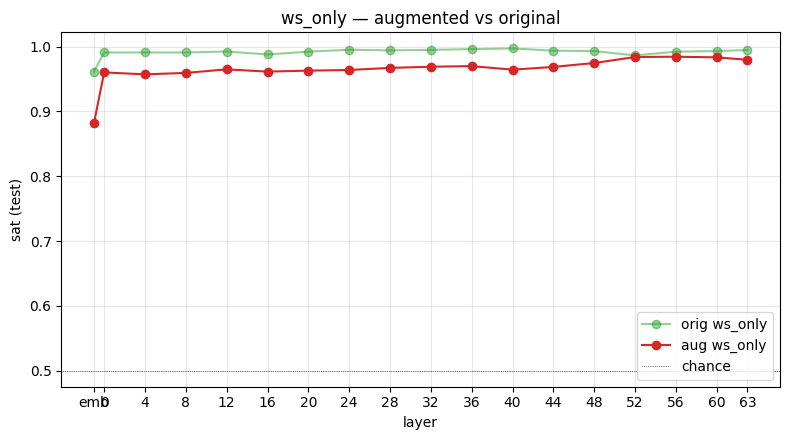


== augmented ws_rows counts ==
       token  span_start       other   frac_pos
       '   '         780       14860      0.050
   '       '          20        9220      0.002
        '\n'        2860        3870      0.425
         ' '           0        6490      0.000
  '           '           0        4750      0.000
  '               '           0        1680      0.000
  '                   '           0         480      0.000
  '                       '           0         130      0.000
  '                           '           0          20      0.000
  '                  '           0          10      0.000
  bucket ('\n', '\n'): n=251
  bucket ('\n\n', '\n\n'): n=0
layer  sat_overall  sat_'\n'  sat_'\n\n'
  emb        0.882     0.000         NaN
    0        0.960     0.829         NaN
    4        0.957     0.785         NaN
    8        0.960     0.829         NaN
   12        0.965     0.849         NaN
   16        0.961     0.841         NaN
   20        0.963     0.837

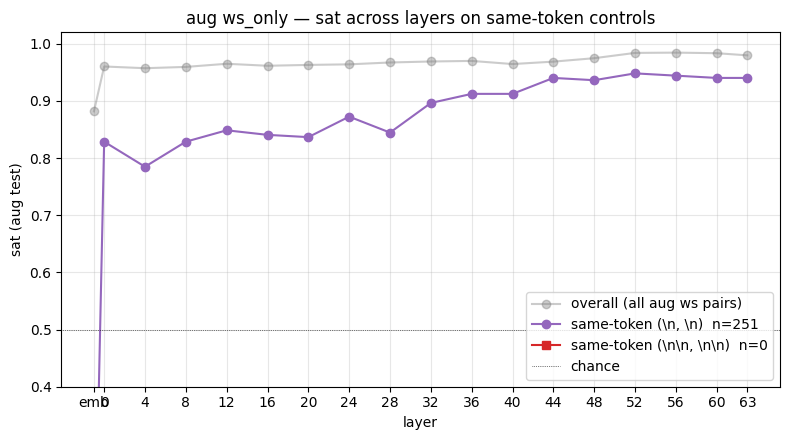

In [65]:
# --- Plot: aug ws_only vs orig ws_only ---------------------------------------
def _xy(results):
    df = pd.DataFrame([{k: r[k] for k in r if not k.startswith("v_")} for r in results])
    df["x"] = df["layer"].map(_plot_x)
    return df.sort_values("x")

df_orig = _xy(ws_sweep_results)
df_aug  = _xy(aug_ws_sweep_results)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_orig["x"], df_orig["sat_test_opt"], "o-", color="tab:green", alpha=0.5, label="orig ws_only")
ax.plot(df_aug["x"],  df_aug["sat_test_opt"],  "o-", color="tab:red", label="aug ws_only")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("sat (test)")
ax.set_title("ws_only — augmented vs original")
apply_layer_axis(ax)
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- Diagnostic 1: per-token-string row counts (augmented) -------------------
from collections import Counter
print("\n== augmented ws_rows counts ==")
tok_pos = Counter(r.first_token_str for r in aug_ws_rows if r.role == "ws_span_start")
tok_neg = Counter(r.first_token_str for r in aug_ws_rows if r.role == "ws_other")
all_toks = sorted(set(tok_pos) | set(tok_neg), key=lambda t: -(tok_pos[t] + tok_neg[t]))
print(f"{'token':>12s}  {'span_start':>10s}  {'other':>10s}  {'frac_pos':>9s}")
for t in all_toks:
    p, n = tok_pos[t], tok_neg[t]
    frac = p / (p + n) if (p + n) else 0.0
    print(f"  {repr(t):>10s}  {p:10d}  {n:10d}  {frac:9.3f}")

# --- Diagnostic 2: per-layer same-token sat on augmented test set ------------
same_buckets = {("\n", "\n"): [], ("\n\n", "\n\n"): []}
for p, n in aug_ws_quads_te:
    k2 = (p.first_token_str, n.first_token_str)
    if k2 in same_buckets:
        same_buckets[k2].append((p, n))
for k, v in same_buckets.items():
    print(f"  bucket {repr(k)}: n={len(v)}")

rows_plot = []
for rec in aug_ws_sweep_results:
    L = rec["layer"]; v_L = rec["v_opt"]
    row = {"layer": L, "sat_overall": rec["sat_test_opt"]}
    for k, qs in same_buckets.items():
        row[f"sat_{repr(k[0])}"] = constraint_sat(v_L, qs, L) if qs else float("nan")
    rows_plot.append(row)
df = pd.DataFrame(rows_plot); df["x"] = df["layer"].map(_plot_x); df = df.sort_values("x")
print(df.drop(columns=["x"]).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df["x"], df["sat_overall"], "o-", color="tab:gray", alpha=0.4,
        label="overall (all aug ws pairs)")
ax.plot(df["x"], df[f"sat_{repr(chr(10))}"], "o-", color="tab:purple",
        label=f"same-token (\\n, \\n)  n={len(same_buckets[(chr(10), chr(10))])}")
ax.plot(df["x"], df[f"sat_{repr(chr(10)*2)}"], "s-", color="tab:red",
        label=f"same-token (\\n\\n, \\n\\n)  n={len(same_buckets[(chr(10)*2, chr(10)*2)])}")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("sat (aug test)")
ax.set_title("aug ws_only — sat across layers on same-token controls")
apply_layer_axis(ax, [r["layer"] for r in aug_ws_sweep_results])
ax.legend(loc="lower right"); ax.grid(alpha=0.3); ax.set_ylim(0.4, 1.02)
plt.tight_layout(); plt.show()


## 11. LAG sweep — is the signal newline-bound, or earlier?

Reuses the trained `v_opt` from the registered probes. For each held-out step with boundary `t_start`, we test the direction at progressively earlier positions:

- positive: token at `t_start − L`
- negative: token at `(t_start + t_end)/2 − L`  (mid-step anchor shifted by same L)

Both pos and neg are shifted by `L` so the comparison stays "boundary vs interior" at increasing distance from the boundary. If the signal lives only at L=1 (the immediate-pre-newline position the probe was trained on), sat collapses to chance as L grows → newline-bound. If sat decays smoothly over several tokens, there's a broader commitment representation.

No retraining; one forward pass per held-out record at each probe's best layer.

probes tested: ['ws', 'ws_aug', 'n1']
        ws: best layer = 40
    ws_aug: best layer = 56
        n1: best layer = 40

held-out records: 42
step anchors: 147


lag-hs:   0%|          | 0/42 [00:00<?, ?it/s]

cached 2748 hidden-state entries

valid pairs per LAG: {1: 147, 2: 146, 3: 146, 5: 134, 10: 113}

sat by (probe, LAG):
       probe  L= 1  L= 2  L= 3  L= 5  L=10
          ws   1.000 0.877 0.726 0.694 0.646
      ws_aug   1.000 0.966 0.699 0.664 0.558
          n1   0.993 0.822 0.719 0.701 0.637


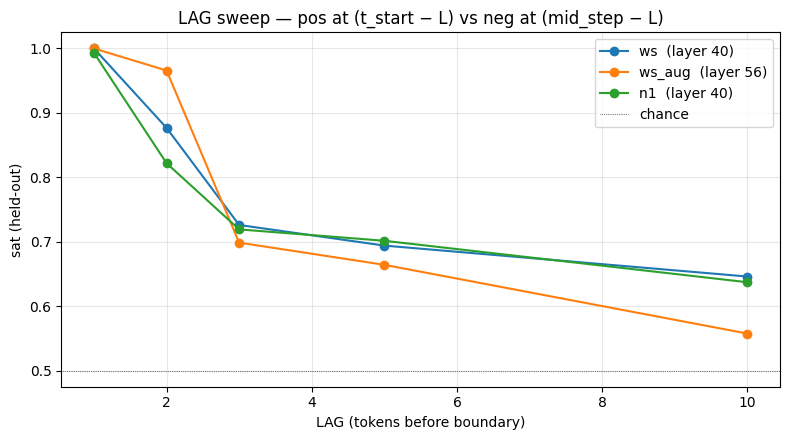

In [75]:
# §11 — LAG sweep on held-out records using already-trained probes.
LAGS = [1, 2, 3, 5, 10]
PROBES = [p for p in ["ws", "ws_aug", "n1"] if p in PROBE_REGISTRY]
print(f"probes tested: {PROBES}")

probe_layers = {name: PROBE_REGISTRY[name]["best_layer"] for name in PROBES}
probe_vs     = {name: get_v(name)[0] for name in PROBES}
for n, L in probe_layers.items():
    print(f"  {n:>8s}: best layer = {_layer_label(L)}")

# ─── Collect (t_start, mid_step) anchors from held-out records ───────────────
records_held = [r for r in records if r["sample_name"] in test_names]
print(f"\nheld-out records: {len(records_held)}")

step_anchors = []
for r in records_held:
    lab = r["labeled"]
    is_mono = r["modularity"] == "monolithic"
    n_steps = len(lab.labels)
    for i, step in enumerate(lab.labels):
        if is_mono and i == n_steps - 1:
            continue
        if step.gen_token_range is None:
            continue
        t_start, t_end = step.gen_token_range
        if t_end - t_start < 4:
            continue
        t_neg = (t_start + t_end) // 2
        step_anchors.append((r, t_start, t_neg))
print(f"step anchors: {len(step_anchors)}")

# ─── Build per-record position set across all LAGs ───────────────────────────
positions_per_rec: dict[tuple, set[int]] = {}
rec_by_key: dict[tuple, dict] = {}
for r, t_start, t_neg in step_anchors:
    key = (r["sample_name"], r["modularity"])
    rec_by_key[key] = r
    s = positions_per_rec.setdefault(key, set())
    for L in LAGS:
        if t_start - L >= 0:
            s.add(t_start - L)
        if t_neg - L > t_start:   # negative must stay inside the step
            s.add(t_neg - L)

unique_layers = sorted(
    set(probe_layers.values()),
    key=lambda x: (-1 if x == "emb" else x),
)

# ─── Forward pass per record to fetch HS at all needed positions ─────────────
@torch.no_grad()
def _fetch_hs(rec, positions, layers):
    combined = rec["labeled"].full_prompt + rec["labeled"].generation
    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    layer_names = [layer_key_to_name(L) for L in layers]
    locations = [(ly, t) for ly in layer_names for t in positions]
    hs_dict = get_hs(mt=mt, input=tokenized, locations=locations, return_dict=True)
    return {
        (L, t): hs_dict[(ly, t)].detach().to("cpu", torch.float32)
        for L, ly in zip(layers, layer_names)
        for t in positions
    }

hs_lag = {}
for key in tqdm(positions_per_rec, desc="lag-hs"):
    rec = rec_by_key[key]
    positions = sorted(positions_per_rec[key])
    for (L, t), h in _fetch_hs(rec, positions, unique_layers).items():
        hs_lag[(key, L, t)] = h
print(f"cached {len(hs_lag)} hidden-state entries")

# ─── Score every pair at every LAG for every probe ───────────────────────────
def _proj(v, h):
    h_u = h / (h.norm() + 1e-9)
    return (v.to(torch.float32) * h_u.to(torch.float32)).sum().item()

sats_per = {name: {L: [] for L in LAGS} for name in PROBES}
n_valid_per_L = {L: 0 for L in LAGS}

for r, t_start, t_neg in step_anchors:
    key = (r["sample_name"], r["modularity"])
    for L in LAGS:
        p_pos = t_start - L
        p_neg = t_neg - L
        if p_pos < 0 or p_neg <= t_start:
            continue
        n_valid_per_L[L] += 1
        for name in PROBES:
            v = probe_vs[name]
            Lp = probe_layers[name]
            h_pos = hs_lag.get((key, Lp, p_pos))
            h_neg = hs_lag.get((key, Lp, p_neg))
            if h_pos is None or h_neg is None:
                continue
            sats_per[name][L].append((_proj(v, h_pos) - _proj(v, h_neg)) > 0)

print(f"\nvalid pairs per LAG: {n_valid_per_L}")
print(f"\nsat by (probe, LAG):")
print(f"  {'probe':>10s}  " + "  ".join(f"L={L:>2d}" for L in LAGS))
for name in PROBES:
    line = f"  {name:>10s}  "
    for L in LAGS:
        ss = sats_per[name][L]
        line += f" {(sum(ss)/len(ss) if ss else float('nan')):.3f}"
    print(line)

# ─── Plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in PROBES:
    ys = [(sum(sats_per[name][L]) / len(sats_per[name][L]))
          if sats_per[name][L] else float("nan") for L in LAGS]
    ax.plot(LAGS, ys, "o-",
            label=f"{name}  (layer {_layer_label(probe_layers[name])})")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("LAG (tokens before boundary)")
ax.set_ylabel("sat (held-out)")
ax.set_title("LAG sweep — pos at (t_start − L) vs neg at (mid_step − L)")
ax.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


---

## ⚠️ Validation TODOs (don't forget)

Even if the §8 ws-only probe survives the diagnostic and the §10 augmentation control, the result is **necessary but not sufficient** for goal-orientedness. The probe still proves only "there exists a linear direction separating these two token sets in offline forward passes." To claim the LM actually *commits to and pursues* a step:

1. **Real test-time generations (no augmentation).** Run the probe online on greedy/sampled generations from held-out prompts — both with and without the §10 augmentations applied at generation time. The direction's activation should track step boundaries on text the LM actually produces.

2. **Proxy / non-code setups.** The whole worry is that code is dominated by surface conventions (`\n\n`, indents, `def`). Re-run the entire commitment-probe pipeline on:
   - **PDDL-style planning** (blocksworld with disjoint goal subsets — note: thinking-mode models needed; non-thinking models fail; see `0_rough.ipynb`).
   - **Math reasoning** (multi-step word problems with clear sub-goal boundaries).
   - **Structured natural-language plans** (recipes, multi-paragraph procedural writeups).
   If the direction generalizes across modalities, we've found a goal-commitment signal, not a code-formatting detector.

3. **Causality.** Steer with the probe direction at non-boundary positions and check whether the LM starts a new step. Ablate at true boundary positions and check whether it merges into the previous step. This is the actual evidence we want for "the direction *encodes* commitment" vs "the direction *correlates with* commitment."

Until (3) lands, treat §8/§10 results as evidence *against* the surface-form null hypothesis, not as evidence *for* goal-orientedness.
